In [1]:

import os
import sys
import torch
import gc
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel , AutoModelForCausalLM, AutoTokenizer
from pathlib import Path
import json
import numpy as np
from collections import defaultdict
import subprocess
import re


print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Number of GPUs:", torch.cuda.device_count())
    
    device = torch.device("cuda")
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))
        print(
            "GPU memory (GB):",
            round(
                torch.cuda.get_device_properties(i).total_memory
                / (1024 ** 3),
                2
            )
        )
torch.cuda.empty_cache()
gc.collect()

print("free memory:")
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.memory_allocated(i)/1024**3:.2f} GB used")

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch version: 2.11.0+cu128
CUDA available: True
Number of GPUs: 2
GPU 0: Tesla T4
GPU memory (GB): 14.56
GPU 1: Tesla T4
GPU memory (GB): 14.56
free memory:
GPU 0: 0.00 GB used
GPU 1: 0.00 GB used


In [2]:

input_dir = "/kaggle/input"

print("Input directory exists:", os.path.exists(input_dir))

for root, dirs, files in os.walk(input_dir):
    for file in files:
        print(os.path.join(root, file))


Input directory exists: True
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/LICENSE_AND_ATTRIBUTION.txt
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/README.txt
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/corpus.jsonl
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/example_predict.py
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/kg_subset_passages.txt
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/labels_dev.jsonl
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/questions_dev.jsonl
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/questions_hidden.jsonl
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/score.py


In [3]:

def find_unique_file(filename):
    matches = list(Path("/kaggle/input").rglob(filename))

    if len(matches) != 1:
        raise ValueError(
            f"Expected exactly one {filename}, found {len(matches)}. "
            "Check the paths printed in the previous cell."
        )

    return matches[0]

CORPUS_PATH = find_unique_file("corpus.jsonl")
QUESTIONS_PATH = find_unique_file("questions_dev.jsonl")
LABELS_PATH = find_unique_file("labels_dev.jsonl")
QUESTIONS_HIDDEN_PATH = find_unique_file("questions_hidden.jsonl")
SCORE_PATH = find_unique_file("score.py")

print("Corpus:", CORPUS_PATH)
print("Questions:", QUESTIONS_PATH)
print("Labels:", LABELS_PATH)
print("Questions Hidden:", QUESTIONS_HIDDEN_PATH)
print("Sorce:", SCORE_PATH)

Corpus: /kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/corpus.jsonl
Questions: /kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/questions_dev.jsonl
Labels: /kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/labels_dev.jsonl
Questions Hidden: /kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/questions_hidden.jsonl
Sorce: /kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/score.py


In [4]:

def read_jsonl(path):
    rows = []

    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                rows.append(json.loads(line))

    return rows

corpus = read_jsonl(CORPUS_PATH)
questions = read_jsonl(QUESTIONS_PATH)
labels = read_jsonl(LABELS_PATH)
questions_hidden = read_jsonl(QUESTIONS_HIDDEN_PATH)


print("Number of documents:", len(corpus))
print("Number of dev questions:", len(questions))
print("Number of dev labels:", len(labels))
print("Number of questions hidden:", len(questions_hidden))


print("\nFirst document:")
print(corpus[0])

print("\nFirst question:")
print(questions[0])

print("\nFirst label:")
print(labels[0])

print("\nFirst question hidden:")
print(questions_hidden[0])



Number of documents: 3882
Number of dev questions: 300
Number of dev labels: 300
Number of questions hidden: 300

First document:
{'doc_id': 'p00001', 'sentences': ['Fannā (Panāh) Khusraw , better known by his laqab of ʿAḍud al-Dawla ("Pillar of the [Abbasid] Dynasty")', '(September 24, 936 – March 26, 983) was an emir of the Buyid dynasty, ruling from 949 to 983, and at his height of power ruling an empire stretching from Makran as far to Yemen and the shores of the Mediterranean Sea.', 'He is widely regarded as the greatest monarch of the dynasty, and by the end of his reign was the most powerful ruler in the Middle East.', 'The son of Rukn al-Dawla, Fanna Khusraw was given the title of Adud al-Dawla by the Abbasid caliph in 948 when he was made emir of Fars after the death of his childless uncle', 'Imad al-Dawla, after which Rukn al-Dawla became the senior emir of the Buyids.', 'In 974 Adud al-Dawla was sent by his father to save his cousin Izz al-Dawla from a rebellion.', 'After de

In [5]:

doc_ids = []
doc_texts = []

for item in corpus:
    doc_id = item["doc_id"]
    title = item.get("title", "").strip()
    text = item.get("text", "").strip()

    if not text:
        text = " ".join(item.get("sentences", [])).strip()

    if not text:
        continue

    formatted_text = f"Title: {title}\nPassage: {text}"

    doc_ids.append(doc_id)
    doc_texts.append(formatted_text)

print("Documents prepared:", len(doc_texts))
print("\nExample input to embedding model:")
print(doc_texts[0])

print("\nUnique document IDs:", len(set(doc_ids)))
print("Duplicate document IDs:", len(doc_ids) - len(set(doc_ids)))

Documents prepared: 3882

Example input to embedding model:
Title: 'Adud al-Dawla
Passage: Fannā (Panāh) Khusraw , better known by his laqab of ʿAḍud al-Dawla ("Pillar of the [Abbasid] Dynasty") (September 24, 936 – March 26, 983) was an emir of the Buyid dynasty, ruling from 949 to 983, and at his height of power ruling an empire stretching from Makran as far to Yemen and the shores of the Mediterranean Sea. He is widely regarded as the greatest monarch of the dynasty, and by the end of his reign was the most powerful ruler in the Middle East. The son of Rukn al-Dawla, Fanna Khusraw was given the title of Adud al-Dawla by the Abbasid caliph in 948 when he was made emir of Fars after the death of his childless uncle Imad al-Dawla, after which Rukn al-Dawla became the senior emir of the Buyids. In 974 Adud al-Dawla was sent by his father to save his cousin Izz al-Dawla from a rebellion. After defeating the rebel forces, he claimed the emirate of Iraq for himself, and forced his cousin t

In [6]:


EMBEDDING_MODEL_NAME = "Qwen/Qwen3-Embedding-4B"

tokenizer = AutoTokenizer.from_pretrained(
    EMBEDDING_MODEL_NAME,
    padding_side="left",
)

model = AutoModel.from_pretrained(
    EMBEDDING_MODEL_NAME,
    dtype=torch.float16,
    device_map="auto",
    max_memory={
        0: "14GiB",
        1: "14GiB",
        "cpu": "48GiB",
    },
)

model.eval()

print("Model loaded")
print("Device map:", model.hf_device_map)

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.26k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

model.safetensors.index.json:   0%|          | 0.00/30.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Model loaded
Device map: {'embed_tokens': 0, 'layers.0': 0, 'layers.1': 0, 'layers.2': 0, 'layers.3': 0, 'layers.4': 0, 'layers.5': 0, 'layers.6': 0, 'layers.7': 0, 'layers.8': 0, 'layers.9': 0, 'layers.10': 0, 'layers.11': 0, 'layers.12': 0, 'layers.13': 0, 'layers.14': 0, 'layers.15': 0, 'layers.16': 1, 'layers.17': 1, 'layers.18': 1, 'layers.19': 1, 'layers.20': 1, 'layers.21': 1, 'layers.22': 1, 'layers.23': 1, 'layers.24': 1, 'layers.25': 1, 'layers.26': 1, 'layers.27': 1, 'layers.28': 1, 'layers.29': 1, 'layers.30': 1, 'layers.31': 1, 'layers.32': 1, 'layers.33': 1, 'layers.34': 1, 'layers.35': 1, 'norm': 1, 'rotary_emb': 1}


In [7]:
@torch.inference_mode()
def make_embeddings(texts, batch_size=2, max_length=1024):
    all_embeddings = []

    input_device = model.get_input_embeddings().weight.device

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]

        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt",
        )

        inputs = {
            key: value.to(input_device)
            for key, value in inputs.items()
        }

        outputs = model(
            **inputs,
            use_cache=False,
            return_dict=True,
        )

        hidden = outputs.last_hidden_state

        # attention_mask = inputs["attention_mask"].to(hidden.device)

        embeddings = hidden[:, -1, :]

        embeddings = F.normalize(embeddings.float(), p=2, dim=1)

        all_embeddings.append(embeddings.cpu())

        del inputs, outputs, hidden, embeddings #, attention_mask

    return torch.cat(all_embeddings, dim=0).numpy()

In [8]:

test_texts = [
    "Title: Example Airport\nPassage: This is a test document.",
    "Title: Example Movie\nPassage: This movie originated in Pakistan.",
]

test_embeddings = make_embeddings(test_texts, batch_size=2)

print("Shape:", test_embeddings.shape)
print("All finite:", np.isfinite(test_embeddings).all())
print("Norms:", np.linalg.norm(test_embeddings, axis=1))
print("Device map:", model.hf_device_map)

Shape: (2, 2560)
All finite: True
Norms: [1. 1.]
Device map: {'embed_tokens': 0, 'layers.0': 0, 'layers.1': 0, 'layers.2': 0, 'layers.3': 0, 'layers.4': 0, 'layers.5': 0, 'layers.6': 0, 'layers.7': 0, 'layers.8': 0, 'layers.9': 0, 'layers.10': 0, 'layers.11': 0, 'layers.12': 0, 'layers.13': 0, 'layers.14': 0, 'layers.15': 0, 'layers.16': 1, 'layers.17': 1, 'layers.18': 1, 'layers.19': 1, 'layers.20': 1, 'layers.21': 1, 'layers.22': 1, 'layers.23': 1, 'layers.24': 1, 'layers.25': 1, 'layers.26': 1, 'layers.27': 1, 'layers.28': 1, 'layers.29': 1, 'layers.30': 1, 'layers.31': 1, 'layers.32': 1, 'layers.33': 1, 'layers.34': 1, 'layers.35': 1, 'norm': 1, 'rotary_emb': 1}


In [9]:


OUTPUT_DIR = Path("/kaggle/working/NLP_phase1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


document_embeddings = make_embeddings(
    doc_texts,
    batch_size=4,
    max_length=1024,  
)

print("Embedding shape:", document_embeddings.shape)
print("Number of documents:", len(doc_ids))
print("All finite:", np.isfinite(document_embeddings).all())
print("First vector norm:", np.linalg.norm(document_embeddings[0]))



output_path = OUTPUT_DIR / "document_embeddings_4B.npz"

np.savez_compressed(
    output_path,
    doc_ids=np.asarray(doc_ids, dtype=str),
    embeddings=document_embeddings.astype(np.float32),
)

print("Saved to:", output_path)

Embedding shape: (3882, 2560)
Number of documents: 3882
All finite: True
First vector norm: 0.99999994
Saved to: /kaggle/working/NLP_phase1/document_embeddings_4B.npz


In [10]:

question_ids = [item["qid"] for item in questions]

query_texts = [
    "Instruct: Given a web search query, retrieve relevant "
    "passages that answer the query\nQuery: "
    + item["question"]
    for item in questions
]

query_embeddings = make_embeddings(
    query_texts,
    batch_size=4,   
    max_length=1024,
)

print("Query embeddings shape:", query_embeddings.shape)
print("All finite:", np.isfinite(query_embeddings).all())
print(
    "First query norm:",
    np.linalg.norm(query_embeddings[0]),
)

assert query_embeddings.shape == (
    len(questions),
    document_embeddings.shape[1],
)


similarities = query_embeddings @ document_embeddings.T

TOP_K = 10

top_indices = np.argsort(
    -similarities,
    axis=1,
)[:, :TOP_K]

top_scores = np.take_along_axis(
    similarities,
    top_indices,
    axis=1,
)

saved_doc_ids = np.asarray(doc_ids, dtype=str)
retrieved_doc_ids = saved_doc_ids[top_indices]

print("Retrieved IDs shape:", retrieved_doc_ids.shape)
print("Retrieved scores shape:", top_scores.shape)



retrieval_path = OUTPUT_DIR / "dev_retrieval_top10.jsonl"

with retrieval_path.open("w", encoding="utf-8") as f:
    for i, question in enumerate(questions):
        record = {
            "qid": question["qid"],
            "question": question["question"],
            "retrieved": retrieved_doc_ids[i].tolist(),
            "scores": [
                float(score) for score in top_scores[i]
            ],
        }

        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("Saved retrieval results to:", retrieval_path)


docs_by_id = {
    str(doc["doc_id"]): doc
    for doc in corpus
}

print("Number of documents:", len(docs_by_id))
print("Example document IDs:", list(docs_by_id.keys())[:5])

assert len(docs_by_id) == len(corpus), "Duplicate or missing document IDs"



print("\nQuestion:", questions[0]["question"])


print("\nRetrieved documents:")

for rank, (doc_id, score) in enumerate(
    zip(retrieved_doc_ids[0], top_scores[0]),
    start=1,
):
    doc = docs_by_id[str(doc_id)]

    print(
        f"{rank:2d}. {doc_id} | "
        f"score={score:.4f} | "
        f"title={doc.get('title', '')}"
    )

Query embeddings shape: (300, 2560)
All finite: True
First query norm: 0.99999994
Retrieved IDs shape: (300, 10)
Retrieved scores shape: (300, 10)
Saved retrieval results to: /kaggle/working/NLP_phase1/dev_retrieval_top10.jsonl
Number of documents: 3882
Example document IDs: ['p00001', 'p00002', 'p00003', 'p00004', 'p00005']

Question: Did the movies Ride A Crooked Trail and The Glassworker, originate from the same country?

Retrieved documents:
 1. p02917 | score=0.6237 | title=Ride a Crooked Trail
 2. p02916 | score=0.5814 | title=Ride a Crooked Mile
 3. p03365 | score=0.5401 | title=The Glassworker
 4. p03320 | score=0.5400 | title=The Crooked Trail
 5. p03691 | score=0.4866 | title=Walk a Crooked Mile
 6. p01334 | score=0.4378 | title=Glass Trap
 7. p02918 | score=0.4247 | title=Ride, Vaquero!
 8. p03452 | score=0.4001 | title=The Rough and the Smooth
 9. p03412 | score=0.3818 | title=The Masked Rider (1919 film)
10. p02609 | score=0.3752 | title=Painted Angels


In [11]:
# ============================================
# Hidden retrieval: Generate embeddings and retrieve top-10 documents
# ============================================

# 1. Prepare hidden questions
hidden_question_ids = [item["qid"] for item in questions_hidden]

hidden_query_texts = [
    "Instruct: Given a web search query, retrieve relevant "
    "passages that answer the query\nQuery: "
    + item["question"]
    for item in questions_hidden
]

print("Number of hidden questions:", len(hidden_query_texts))

# 2. Generate hidden query embeddings using the currently loaded model
hidden_query_embeddings = make_embeddings(
    hidden_query_texts,
    batch_size=4,
    max_length=1024,
)

print("Hidden query embeddings shape:", hidden_query_embeddings.shape)
print("All finite:", np.isfinite(hidden_query_embeddings).all())

assert hidden_query_embeddings.shape == (
    len(questions_hidden),
    document_embeddings.shape[1],
)

assert np.isfinite(hidden_query_embeddings).all()

# 3. Compute similarity against existing document embeddings
similarities_hidden = hidden_query_embeddings @ document_embeddings.T

TOP_K = 10

top_indices_hidden = np.argsort(
    -similarities_hidden,
    axis=1,
)[:, :TOP_K]

top_scores_hidden = np.take_along_axis(
    similarities_hidden,
    top_indices_hidden,
    axis=1,
)

# Use the same document-ID ordering as document_embeddings
saved_doc_ids = np.asarray(doc_ids, dtype=str)
retrieved_doc_ids_hidden = saved_doc_ids[top_indices_hidden]

print("Retrieved IDs shape:", retrieved_doc_ids_hidden.shape)
print("Retrieved scores shape:", top_scores_hidden.shape)

# 4. Save hidden retrieval results
hidden_retrieval_path = OUTPUT_DIR / "hidden_retrieval_top10.jsonl"

with hidden_retrieval_path.open("w", encoding="utf-8") as f:
    for i, question in enumerate(questions_hidden):
        record = {
            "qid": question["qid"],
            "question": question["question"],
            "retrieved": retrieved_doc_ids_hidden[i].tolist(),
            "scores": [
                float(score) for score in top_scores_hidden[i]
            ],
        }

        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("Saved hidden retrieval results to:", hidden_retrieval_path)

# 5. Build a qid -> retrieved document IDs mapping for hidden RAG
hidden_retrieval_map = {
    str(question["qid"]): retrieved_doc_ids_hidden[i].tolist()
    for i, question in enumerate(questions_hidden)
}

assert len(hidden_retrieval_map) == len(questions_hidden)
assert all(
    len(doc_ids_list) == TOP_K
    for doc_ids_list in hidden_retrieval_map.values()
)

print("Hidden retrieval map created:", len(hidden_retrieval_map))
print("Example qid:", hidden_question_ids[0])
print("Example retrieved documents:", hidden_retrieval_map[str(hidden_question_ids[0])][:5])

Number of hidden questions: 300
Hidden query embeddings shape: (300, 2560)
All finite: True
Retrieved IDs shape: (300, 10)
Retrieved scores shape: (300, 10)
Saved hidden retrieval results to: /kaggle/working/NLP_phase1/hidden_retrieval_top10.jsonl
Hidden retrieval map created: 300
Example qid: q1001
Example retrieved documents: ['p02089', 'p00780', 'p00334', 'p01595', 'p03492']


In [12]:

question_index = {
    str(q["qid"]): i
    for i, q in enumerate(questions)
}


question_text_index = {
    q["question"]: i
    for i, q in enumerate(questions)
}

doc_id_to_index = {
    str(doc_id): i
    for i, doc_id in enumerate(saved_doc_ids)
}

assert similarities.shape == (
    len(questions),
    len(saved_doc_ids)
)

def dense_search(query, k=10, exclude_ids=frozenset()):

    if k <= 0:
        raise ValueError("k must be positive")

    if query not in question_text_index:
        raise ValueError(
            "Query not found in question list."
        )

    row = question_text_index[query]
    scores = similarities[row].copy()


    for doc_id in exclude_ids:
        doc_id = str(doc_id)
        if doc_id in doc_id_to_index:
            scores[doc_id_to_index[doc_id]] = -np.inf

    k_actual = min(k, len(saved_doc_ids) - len({
        str(x) for x in exclude_ids if str(x) in doc_id_to_index
    }))

    if k_actual <= 0:
        return []


    ranked_indices = np.argsort(-scores)[:k_actual]

    return [str(saved_doc_ids[i]) for i in ranked_indices]

In [13]:

K_VALUES = [2, 5, 10]

def retrieval_metrics(retrieved_ids, gold_ids):

    retrieved_ids = [str(x) for x in retrieved_ids]
    gold_ids = set(str(x) for x in gold_ids)

    if not gold_ids:
        raise ValueError("Gold document list is empty.")

    result = {}

    for k in K_VALUES:
        top_k = retrieved_ids[:k]
        found = set(top_k) & gold_ids

        result[f"Recall@{k}"] = len(found) / len(gold_ids)
        result[f"HitAll@{k}"] = float(gold_ids.issubset(set(top_k)))


    # top_10 = retrieved_ids[:10]

        dcg = sum(
            1.0 / np.log2(rank + 1)
            for rank, doc_id in enumerate(top_k, start=1)
            if doc_id in gold_ids
        )

        ideal_relevant = min(len(gold_ids), k)

        idcg = sum(
            1.0 / np.log2(rank + 1)
            for rank in range(1, ideal_relevant + 1)
        )

        result[f"nDCG@{k}"] = dcg / idcg if idcg > 0 else 0.0
        
    reciprocal_rank = 0.0
    for rank, doc_id in enumerate(retrieved_ids, start=1):
        if doc_id in gold_ids:
            reciprocal_rank = 1.0 / rank
            break

    result["MRR"] = reciprocal_rank

    return result

In [14]:

labels_by_qid = {
    item["qid"]: item
    for item in labels
}

assert set(question_ids) == set(labels_by_qid)

all_metrics = []

for i, qid in enumerate(question_ids):
    gold_ids = labels_by_qid[qid]["gold_doc_ids"]
    retrieved_ids = retrieved_doc_ids[i].tolist()   
    
    metrics = retrieval_metrics(retrieved_ids, gold_ids)
    all_metrics.append(metrics)
    
for k in [2, 5, 10]:
    recall_key = f"Recall@{k}"
    hitall_key = f"HitAll@{k}"
    
    mean_recall = np.mean([m[recall_key] for m in all_metrics])
    mean_hitall = np.mean([m[hitall_key] for m in all_metrics])
    
    print(f"{recall_key}: {mean_recall:.4f} | {hitall_key}: {mean_hitall:.4f}")

mean_mrr = np.mean([m["MRR"] for m in all_metrics])
mean_ndcg = np.mean([m["nDCG@10"] for m in all_metrics])

print(f"MRR: {mean_mrr:.4f}")
print(f"nDCG@10: {mean_ndcg:.4f}")



Recall@2: 0.6550 | HitAll@2: 0.3200
Recall@5: 0.7542 | HitAll@5: 0.4833
Recall@10: 0.7917 | HitAll@10: 0.5533
MRR: 0.9883
nDCG@10: 0.8060


In [15]:



if "embedding_model" in globals():
    del embedding_model

if "model" in globals():
    del model

if "tokenizer" in globals():
    del tokenizer

gc.collect()
torch.cuda.empty_cache()

LLM_MODEL_NAME = "Qwen/Qwen3-8B"

assert torch.cuda.is_available(), "CUDA is not available"
assert torch.cuda.device_count() >= 2, "2 or more CUDA is  available"

llm_tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL_NAME)

llm_model = AutoModelForCausalLM.from_pretrained(
    LLM_MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    max_memory={
        0: "14GiB",
        1: "14GiB",
    },
)

llm_model.eval()

print("LLM loaded successfully.")
print("Device map:", llm_model.hf_device_map)

for i in range(torch.cuda.device_count()):
    print(
        f"GPU {i}: "
        f"{torch.cuda.memory_allocated(i) / 1024**3:.2f} GiB allocated"
    )


config.json:   0%|          | 0.00/728 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

LLM loaded successfully.
Device map: {'model.embed_tokens': 0, 'model.layers.0': 0, 'model.layers.1': 0, 'model.layers.2': 0, 'model.layers.3': 0, 'model.layers.4': 0, 'model.layers.5': 0, 'model.layers.6': 0, 'model.layers.7': 0, 'model.layers.8': 0, 'model.layers.9': 0, 'model.layers.10': 0, 'model.layers.11': 0, 'model.layers.12': 0, 'model.layers.13': 0, 'model.layers.14': 0, 'model.layers.15': 0, 'model.layers.16': 1, 'model.layers.17': 1, 'model.layers.18': 1, 'model.layers.19': 1, 'model.layers.20': 1, 'model.layers.21': 1, 'model.layers.22': 1, 'model.layers.23': 1, 'model.layers.24': 1, 'model.layers.25': 1, 'model.layers.26': 1, 'model.layers.27': 1, 'model.layers.28': 1, 'model.layers.29': 1, 'model.layers.30': 1, 'model.layers.31': 1, 'model.layers.32': 1, 'model.layers.33': 1, 'model.layers.34': 1, 'model.layers.35': 1, 'model.norm': 1, 'model.rotary_emb': 1, 'lm_head': 1}
GPU 0: 6.92 GiB allocated
GPU 1: 8.35 GiB allocated


In [16]:

@torch.inference_mode()
def generate_answer(
    question,
    context_docs=None,
    max_new_tokens=96,
):
    if context_docs:
        context_parts = []

        for doc in context_docs:
            doc_id = doc["doc_id"]
            title = doc.get("title", "")
            text = doc.get("text", "")

            context_parts.append(
                f"[{doc_id}]\nTitle: {title}\nPassage: {text}"
            )

        context = "\n\n".join(context_parts)

        user_prompt = f"""
Answer the question using the provided documents.

Rules:
Answer rules:
1. Output ONLY the shortest phrase that directly answers the question (usually 1-6 words). No full sentences, no explanations, no reasoning.
2. Never start with "Based on the passages", "According to the passages", or "The answer is". Never restate the question.
3. If the question is yes/no, output exactly "Yes" or "No".
4. If the passages contain the answer, always output it - do not say the information is missing.

5. For questions asking who, where, when, or which, return only the requested name, place, date, or item.
6. In the document-based setting, cite all supporting documents using IDs like [p00005].
7. If the documents do not contain enough information, return exactly:
INSUFFICIENT_INFORMATION

Documents:
{context}

Question: {question}

Answer:
"""
    else:
        user_prompt = f"""
Answer the question using your own knowledge.

Rules:
- Respond with ONLY the short final answer. Do not explain.
- For yes/no questions, answer exactly "yes" or "no".
- For entity questions, provide only the requested entity or name.
- Do not invent document citations.

Question: {question}

Answer:
"""


    messages = [
        {
            "role": "system",
            "content": (
                "You are a question-answering system. "
                "Answer concisely and follow the requested format."
            ),
        },
        {"role": "user", "content": user_prompt},
    ]

    formatted_prompt = llm_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )

    inputs = llm_tokenizer(
        formatted_prompt,
        return_tensors="pt",
        truncation=True,
        max_length=4096,
    )

    input_device = llm_model.get_input_embeddings().weight.device
    inputs = {
        key: value.to(input_device)
        for key, value in inputs.items()
    }

    generated = llm_model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        use_cache=True,
        pad_token_id=llm_tokenizer.eos_token_id,
    )


    prompt_length = inputs["input_ids"].shape[1]
    new_tokens = generated[0][prompt_length:]

    answer = llm_tokenizer.decode(
        new_tokens,
        skip_special_tokens=True,
    ).strip()


    abstained = "INSUFFICIENT_INFORMATION" in answer.upper()

    if abstained:
        return {
            "answer": "",
            "cited": [],
            "abstained": True,
        }

    cited_ids = list(dict.fromkeys(
        c.lower() for c in re.findall(r"\b(p\d{5})\b", answer, flags=re.IGNORECASE)
    ))
    # cited_ids = list(dict.fromkeys(
    #     re.findall(r"\[(p\d{5})\]", answer)
    # ))


    clean_answer = re.sub(r"\[p\d{5}\]", "", answer)


    clean_answer = re.sub(r"\s+", " ", clean_answer).strip()


    clean_answer = re.sub(r"[\s.,;:!?]+$", "", clean_answer).strip()

    return {
        "answer": clean_answer,
        "cited": cited_ids,
        "abstained": False,
    }
    # answer = llm_tokenizer.decode(
    #     new_tokens,
    #     skip_special_tokens=True,
    # ).strip()


    # abstained = "INSUFFICIENT_INFORMATION" in answer.upper()

    # if abstained:
    #     return {
    #         "answer": "",
    #         "cited": [],
    #         "abstained": True,
    #     }


    # cited_ids = list(dict.fromkeys(
    #     re.findall(r"\[(p\d{5})\]", answer)
    # ))


    # clean_answer = re.sub(r"\[p\d{5}\]", "", answer)
    # clean_answer = re.sub(r"\s+", " ", clean_answer).strip()

    # return {
    #     "answer": clean_answer,
    #     "cited": cited_ids,
    #     "abstained": False,
    # }
    

In [17]:

test_result = generate_answer(
    "Did the movies Ride A Crooked Trail and The Glassworker originate from the same country?",
    context_docs=None,
)

print("Answer:", test_result["answer"])
print("Cited:", test_result["cited"])
print("Abstained:", test_result["abstained"])


Answer: no
Cited: []
Abstained: False


In [18]:

# LIMIT = 1 #None

# question_items = list(questions)
# if LIMIT is not None:
#     question_items = question_items[:LIMIT]

def get_context(doc_ids):
    return [
        docs_by_id[doc_id]
        for doc_id in doc_ids
        if doc_id in docs_by_id
    ]

def run_method(method_name, question_items , retrieval_map=None , tag=None):
    
    # output_path = OUTPUT_DIR / f"predictions_{method_name}.jsonl"
    file_suffix = f"_{tag}" if tag else ""
    output_path = OUTPUT_DIR / f"predictions_{method_name}{file_suffix}.jsonl"
    
    results = []
    with output_path.open("w", encoding="utf-8") as f:
        for i, item in enumerate(question_items, start=1):
            qid = item["qid"]
            question = item["question"]

            if method_name == "closed_book":
                context_docs = None
                retrieved = []

            elif method_name == "oracle_context":
                # gold_ids = labels_by_qid[qid]["gold_doc_ids"]
                # context_docs = get_context(gold_ids)
                gold_ids = [
                    str(doc_id)
                    for doc_id in labels_by_qid[str(qid)]["gold_doc_ids"]
                ]

                context_docs = [
                    docs_by_id[doc_id]
                    for doc_id in gold_ids
                ]
                retrieved = gold_ids
                
            elif method_name == "dense_rag":
                if retrieval_map is not None:
                    # Hidden: use precomputed hidden retrieval results
                    all_retrieved_ids = [
                        str(doc_id)
                        for doc_id in retrieval_map[str(qid)][:10]
                    ]
                else:
                    # Dev: use existing dense retrieval
                    all_retrieved_ids = [
                        str(doc_id)
                        for doc_id in dense_search(question, k=10)
                    ]

                retrieved = all_retrieved_ids
                
                context_ids = all_retrieved_ids[:10]
                context_docs = get_context(context_ids)
                # context_ids = all_retrieved_ids[:5]
                # context_docs = get_context(context_ids)
            # elif method_name == "dense_rag":
            #     row_index = next(
            #         j for j, q in enumerate(questions)
            #         if q["qid"] == qid
            #     )
            #     top_ids = list(retrieved_doc_ids[row_index][:5])
            #     top_ids = [str(x) for x in top_ids]
            #     # context_docs = get_context(top_ids)
                
            #     all_retrieved_ids = dense_search(
            #         question,    #["question"],
            #         k=10
            #     )

            #     context_ids = all_retrieved_ids[:5]

            #     context_docs = [
            #         docs_by_id[doc_id]
            #         for doc_id in context_ids
            #     ]
                
            #     retrieved = all_retrieved_ids #top_ids
            else:
                raise ValueError(f"Unknown method: {method_name}")

            result = generate_answer(
                question,
                context_docs=context_docs,
                max_new_tokens=128,
            )

            record = {
                "qid": qid,
                "answer": result["answer"],
                "retrieved": retrieved,
                "cited": result["cited"],
                "abstained": result["abstained"],
            }
            results.append(record)
            f.write(json.dumps(record, ensure_ascii=False) + "\n")

            display_answer = (
                "INSUFFICIENT_INFORMATION"
                if result["abstained"]
                else result["answer"]
            )

            if not result["answer"] and not result["abstained"]:
                display_answer = "[EMPTY_GENERATION]"

            print(
                f"{i}/{len(question_items)} | {method_name} | "
                f"{qid} | {display_answer}"
            )
            # print(
            #     f"{i}/{len(question_items)} | {method_name} | "
            #     f"{qid} | {result['answer']}"
            # )
   
    print("Saved:", output_path)
    return results

# for method in ["closed_book", "oracle_context", "dense_rag"]:
#     run_method(method, question_items)


In [19]:


# retrieved_by_qid = {
#     str(q["qid"]): dense_search(q["question"], k=10)
#     for q in questions
# }

# assert len(retrieved_by_qid) == len(questions) == 300
# assert set(retrieved_by_qid) == set(labels_by_qid)

per_question_metrics = {}

for q in questions:
    qid = str(q["qid"])
    gold_ids = labels_by_qid[qid]["gold_doc_ids"]

    # per_question_metrics[qid] = retrieval_metrics(
    #     retrieved_by_qid[qid],
    #     gold_ids
    # )
    per_question_metrics = {
        str(q["qid"]): retrieval_metrics(
            retrieved_doc_ids[i].tolist(),
            labels_by_qid[str(q["qid"])]["gold_doc_ids"],
        )
        for i, q in enumerate(questions)
    }

metric_names = [
    "Recall@2", "Recall@5", "Recall@10",
    "HitAll@2", "HitAll@5", "HitAll@10",
    "MRR", "nDCG@10"
]

retrieval_summary = {
    name: float(np.mean([
        per_question_metrics[qid][name]
        for qid in per_question_metrics
    ]))
    for name in metric_names
}

print("Dense Retrieval Metrics on dev")
for name, value in retrieval_summary.items():
    print(f"{name}: {value:.4f}")

Dense Retrieval Metrics on dev
Recall@2: 0.6550
Recall@5: 0.7542
Recall@10: 0.7917
HitAll@2: 0.3200
HitAll@5: 0.4833
HitAll@10: 0.5533
MRR: 0.9883
nDCG@10: 0.8060


In [20]:

for method in ["closed_book", "oracle_context", "dense_rag"]:
    path = OUTPUT_DIR / f"predictions_{method}.jsonl"

    print(f"\n--- {method} ---")

    if not path.exists():
        print(f"file not found: {path}")
        continue

    with path.open("r", encoding="utf-8") as f:
        for line in list(f)[:2]:
            print(json.loads(line))
        

# for method in ["closed_book", "oracle_context", "dense_rag"]:
#     path = OUTPUT_DIR / f"predictions_{method}.jsonl"

#     print(f"\n--- {method} ---")

#     with path.open("r", encoding="utf-8") as f:
#         for line in list(f)[:2]:
#             print(json.loads(line))



--- closed_book ---
file not found: /kaggle/working/NLP_phase1/predictions_closed_book.jsonl

--- oracle_context ---
file not found: /kaggle/working/NLP_phase1/predictions_oracle_context.jsonl

--- dense_rag ---
file not found: /kaggle/working/NLP_phase1/predictions_dense_rag.jsonl


In [21]:

metrics_by_type = defaultdict(list)

for q in questions:
    qid = str(q["qid"])
    qtype = q["type"]

    metrics_by_type[qtype].append(
        per_question_metrics[qid]
    )

print("Retrieval metrics by question type")

for qtype, rows in sorted(metrics_by_type.items()):
    print(f"\nQuestion type: {qtype}")

    for name in metric_names:
        value = np.mean([row[name] for row in rows])
        print(f"{name}: {value:.4f}")

Retrieval metrics by question type

Question type: bridge_comparison
Recall@2: 0.4773
Recall@5: 0.5568
Recall@10: 0.5758
HitAll@2: 0.0000
HitAll@5: 0.0000
HitAll@10: 0.0152
MRR: 1.0000
nDCG@10: 0.6825

Question type: comparison
Recall@2: 0.9041
Recall@5: 1.0000
Recall@10: 1.0000
HitAll@2: 0.8082
HitAll@5: 1.0000
HitAll@10: 1.0000
MRR: 0.9795
nDCG@10: 0.9741

Question type: compositional
Recall@2: 0.6160
Recall@5: 0.6960
Recall@10: 0.7520
HitAll@2: 0.2320
HitAll@5: 0.3920
HitAll@10: 0.5040
MRR: 0.9960
nDCG@10: 0.7676

Question type: inference
Recall@2: 0.6111
Recall@5: 0.8194
Recall@10: 0.9028
HitAll@2: 0.2222
HitAll@5: 0.6389
HitAll@10: 0.8056
MRR: 0.9583
nDCG@10: 0.8248


In [22]:
REQUIRED_FIELDS = {
    "qid",
    "answer",
    "retrieved",
    "cited",
    "abstained",
}

def validate_predictions(predictions, question_items, docs_by_id):
    expected_qids = [str(q["qid"]) for q in question_items]
    actual_qids = [str(p["qid"]) for p in predictions]

    assert len(actual_qids) == len(expected_qids), (
        f"Expected {len(expected_qids)} rows, got {len(actual_qids)}"
    )
    assert len(actual_qids) == len(set(actual_qids)), (
        "Duplicate qid found."
    )
    assert set(actual_qids) == set(expected_qids), (
        "Missing or unexpected qids."
    )

    for row in predictions:
        assert set(row.keys()) == REQUIRED_FIELDS, (
            f"Invalid fields in {row.get('qid')}: {row.keys()}"
        )

        assert isinstance(row["answer"], str)
        assert isinstance(row["retrieved"], list)
        assert isinstance(row["cited"], list)
        assert isinstance(row["abstained"], bool)

        assert len(row["retrieved"]) == len(set(row["retrieved"])), (
            f"Duplicate retrieved IDs in {row['qid']}"
        )

        assert all(str(x) in docs_by_id for x in row["retrieved"]), (
            f"Unknown retrieved document in {row['qid']}"
        )

        assert all(str(x) in docs_by_id for x in row["cited"]), (
            f"Unknown cited document in {row['qid']}"
        )

    print(f"Validation passed: {len(predictions)} predictions")

In [23]:


PACK_DIR = Path(CORPUS_PATH).parent
SCORE_PATH = PACK_DIR / "score.py"

print("Dataset directory:", PACK_DIR)
print("Score script exists:", SCORE_PATH.exists())

assert SCORE_PATH.exists(), (
    "score.py was not found beside corpus.jsonl"
)

Dataset directory: /kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1
Score script exists: True


In [24]:


RUNS_DIR = OUTPUT_DIR / "runs"

print("OUTPUT_DIR exists:", OUTPUT_DIR.exists())
print("RUNS_DIR exists:", RUNS_DIR.exists())

print("\nExisting JSONL files:")
for path in sorted(Path("/kaggle/working").rglob("*.jsonl")):
    print(path)

print("\nExisting YAML files:")
for path in sorted(Path("/kaggle/working").rglob("run_config.yaml")):
    print(path)

OUTPUT_DIR exists: True
RUNS_DIR exists: False

Existing JSONL files:
/kaggle/working/NLP_phase1/dev_retrieval_top10.jsonl
/kaggle/working/NLP_phase1/hidden_retrieval_top10.jsonl

Existing YAML files:


In [25]:


RUN_PATHS = {
    "closed_book": RUNS_DIR / "dev" / "closed_book",
    "oracle_context": RUNS_DIR / "dev" / "oracle",
    "dense_rag": RUNS_DIR / "dev" / "dense",
    "hidden_closed_book": RUNS_DIR / "hidden" / "closed_book",
    "hidden_dense_rag": RUNS_DIR / "hidden" / "dense",
}

for path in RUN_PATHS.values():
    path.mkdir(parents=True, exist_ok=True)

def save_predictions(predictions, output_path):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    required_fields = {
        "qid", "answer", "retrieved", "cited", "abstained"
    }

    with output_path.open("w", encoding="utf-8") as f:
        for row in predictions:
            record = {
                "qid": str(row["qid"]),
                "answer": str(row["answer"]),
                "retrieved": [str(x) for x in row["retrieved"]],
                "cited": [str(x) for x in row["cited"]],
                "abstained": bool(row["abstained"]),
            }

            assert set(record) == required_fields
            f.write(json.dumps(record, ensure_ascii=False) + "\n")

    print(f"Saved {len(predictions)} predictions -> {output_path}")

In [26]:

import random
import subprocess
import sys


random.seed(64)
sample_qids = set(
    random.sample([q["qid"] for q in questions], 50)
)

selfcheck_items = [
    q for q in questions
    if q["qid"] in sample_qids
]

assert len(selfcheck_items) == 50, (
    f"Expected 50 questions, got {len(selfcheck_items)}"
)

selfcheck_predictions = run_method(
    "oracle_context",
    selfcheck_items,
    tag="selfcheck",
)

SELF_CHECK_DIR = OUTPUT_DIR / "runs" / "selfcheck"
SELF_CHECK_DIR.mkdir(parents=True, exist_ok=True)

SELF_CHECK_PATH = SELF_CHECK_DIR / "predictions.jsonl"

save_predictions(
    selfcheck_predictions,
    SELF_CHECK_PATH,
)

result = subprocess.run(
    [
        sys.executable,
        str(SCORE_PATH),
        str(SELF_CHECK_PATH),
        "--pack", str(PACK_DIR),
        "--split", "dev",
        "--partial",
    ],
    text=True,
    capture_output=True,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Self-check scoring failed.")

print("\nSelf-check predictions:", SELF_CHECK_PATH)


1/50 | oracle_context | q0001 | No
2/50 | oracle_context | q0003 | England
3/50 | oracle_context | q0009 | Junior Mandrake
4/50 | oracle_context | q0013 | New York City
5/50 | oracle_context | q0016 | Austrian
6/50 | oracle_context | q0024 | Weston-super-Mare, Somerset
7/50 | oracle_context | q0026 | Princeton, New Jersey
8/50 | oracle_context | q0029 | Hannover or Hamburg
9/50 | oracle_context | q0033 | The Students of Springfield Street
10/50 | oracle_context | q0041 | Heartbroken On The Moselle
11/50 | oracle_context | q0043 | Saffron Walden
12/50 | oracle_context | q0046 | Poland
13/50 | oracle_context | q0054 | We're Going To Be Rich
14/50 | oracle_context | q0064 | German
15/50 | oracle_context | q0071 | Ukiah, California
16/50 | oracle_context | q0076 | Yaadein (1964 Film)
17/50 | oracle_context | q0083 | Princess Maria Beatrice of Savoy
18/50 | oracle_context | q0090 | Queen Munjeong
19/50 | oracle_context | q0092 | The Ballad of Gregorio Cortez
20/50 | oracle_context | q0101 |

In [27]:
HIDDEN_QUESTIONS_PATH = PACK_DIR / "questions_hidden.jsonl"

questions_hidden = read_jsonl(HIDDEN_QUESTIONS_PATH)

print("Hidden questions:", len(questions_hidden))
print("Example:", questions_hidden[0])

Hidden questions: 300
Example: {'qid': 'q1001', 'question': 'Which film has the director who was born first, Cross Of Love or Ljuvlig Är Sommarnatten?', 'type': 'bridge_comparison'}


In [28]:
hidden_items = list(questions_hidden)

hidden_closed_predictions = run_method(
    "closed_book",
    hidden_items
)

save_predictions(
    hidden_closed_predictions,
    RUN_PATHS["hidden_closed_book"] / "predictions.jsonl"
)

1/300 | closed_book | q1001 | Ljuvlig Är Sommarnatten
2/300 | closed_book | q1002 | Salad By The Roots
3/300 | closed_book | q1003 | London, England
4/300 | closed_book | q1004 | Ek Haseena Thi Ek Deewana Tha
5/300 | closed_book | q1005 | The Slaughter Rule
6/300 | closed_book | q1006 | Atlanta, Georgia
7/300 | closed_book | q1007 | Cloud Dancer
8/300 | closed_book | q1008 | Bucharest
9/300 | closed_book | q1009 | Benjamin Nash
10/300 | closed_book | q1010 | no
11/300 | closed_book | q1011 | Born in New York City, New York, United States
12/300 | closed_book | q1012 | Lương Hoàng Nam
13/300 | closed_book | q1013 | no
14/300 | closed_book | q1014 | Illang: The Wolf Brigade
15/300 | closed_book | q1015 | Italian
16/300 | closed_book | q1016 | Los Angeles, California
17/300 | closed_book | q1017 | Nicholas II of Russia
18/300 | closed_book | q1018 | Marius Mapou
19/300 | closed_book | q1019 | University of California, Berkeley
20/300 | closed_book | q1020 | Margaret of France
21/300 | clo

In [29]:
hidden_closed_path = (
    RUN_PATHS["hidden_closed_book"] / "predictions.jsonl"
)

print("File exists:", hidden_closed_path.exists())

if hidden_closed_path.exists():
    with hidden_closed_path.open("r", encoding="utf-8") as f:
        print("Prediction count:", sum(1 for line in f if line.strip()))

File exists: True
Prediction count: 300


In [30]:
hidden_closed_path = (
    RUN_PATHS["hidden_closed_book"] / "predictions.jsonl"
)

assert hidden_closed_path.exists()

with hidden_closed_path.open("r", encoding="utf-8") as f:
    hidden_closed_rows = [
        json.loads(line)
        for line in f
        if line.strip()
    ]

print("Number of predictions:", len(hidden_closed_rows))
print("First prediction:", hidden_closed_rows[0])

assert len(hidden_closed_rows) == len(questions_hidden)
validate_predictions(
    hidden_closed_rows,
    questions_hidden,
    docs_by_id
)

Number of predictions: 300
First prediction: {'qid': 'q1001', 'answer': 'Ljuvlig Är Sommarnatten', 'retrieved': [], 'cited': [], 'abstained': False}
Validation passed: 300 predictions


In [31]:

LIMIT = None
question_items = list(questions)
if LIMIT is not None:
    question_items = question_items[:LIMIT]

# assert len(question_items) == 300

dev_closed_predictions = run_method(
    "closed_book", question_items
)

dev_oracle_predictions = run_method(
    "oracle_context", question_items
)

dev_dense_predictions = run_method(
    "dense_rag", question_items
)


assert isinstance(dev_closed_predictions, list)
assert isinstance(dev_oracle_predictions, list)
assert isinstance(dev_dense_predictions, list)


save_predictions(
    dev_closed_predictions,
    RUN_PATHS["closed_book"] / "predictions.jsonl"
)

save_predictions(
    dev_oracle_predictions,
    RUN_PATHS["oracle_context"] / "predictions.jsonl"
)

save_predictions(
    dev_dense_predictions,
    RUN_PATHS["dense_rag"] / "predictions.jsonl"
)

1/300 | closed_book | q0001 | no
2/300 | closed_book | q0002 | Escape From L.A
3/300 | closed_book | q0003 | England
4/300 | closed_book | q0004 | Nina Škottová
5/300 | closed_book | q0005 | Heart failure due to a long-standing illness
6/300 | closed_book | q0006 | Albanian
7/300 | closed_book | q0007 | Copenhagen
8/300 | closed_book | q0008 | no
9/300 | closed_book | q0009 | Junior Mandrake
10/300 | closed_book | q0010 | Kentucky
11/300 | closed_book | q0011 | Robot Jox
12/300 | closed_book | q0012 | Mark Of The Frog
13/300 | closed_book | q0013 | Los Angeles, California
14/300 | closed_book | q0014 | Paris
15/300 | closed_book | q0015 | no
16/300 | closed_book | q0016 | German
17/300 | closed_book | q0017 | London
18/300 | closed_book | q0018 | American
19/300 | closed_book | q0019 | Alexander II of Russia
20/300 | closed_book | q0020 | Edward Venables-Vernon-Harcourt's paternal grandfather is Henry Harcourt
21/300 | closed_book | q0021 | Antiochus I Soter
22/300 | closed_book | q002

In [32]:
print("closed_book:", type(dev_closed_predictions))
print("oracle:", type(dev_oracle_predictions))
print("dense_rag:", type(dev_dense_predictions))

closed_book: <class 'list'>
oracle: <class 'list'>
dense_rag: <class 'list'>


In [33]:

import re
import string
from collections import Counter

def normalize_answer(text):
    text = str(text).lower()
    text = "".join(
        ch for ch in text
        if ch not in string.punctuation
    )
    return " ".join(
        re.sub(r"\b(a|an|the)\b", " ", text).split()
    )

def prediction_is_correct(pred, label):
    if pred.get("abstained", False):
        return False

    answer = normalize_answer(pred.get("answer", ""))
    gold_answers = [label["answer"]] + label.get("aliases", [])

    return any(
        answer == normalize_answer(gold)
        for gold in gold_answers
    )

def hit_all_at_10(pred, label):
    retrieved = set(map(str, pred.get("retrieved", [])[:10]))
    gold = set(map(str, label["gold_doc_ids"]))
    return gold.issubset(retrieved)

questions_by_qid = {
    str(q["qid"]): q for q in questions
}
labels_by_qid_str = {
    str(qid): label for qid, label in labels_by_qid.items()
}
oracle_by_qid = {
    str(p["qid"]): p for p in dev_oracle_predictions
}
dense_by_qid = {
    str(p["qid"]): p for p in dev_dense_predictions
}


retrieval_failures = []

for qid, question_item in questions_by_qid.items():
    if qid not in dense_by_qid or qid not in labels_by_qid_str:
        continue

    label = labels_by_qid_str[qid]
    dense_pred = dense_by_qid[qid]

    if not hit_all_at_10(dense_pred, label):
        retrieval_failures.append({
            "qid": qid,
            "question": question_item["question"],
            "type": question_item.get("type", "unknown"),
            "gold_answer": label["answer"],
            "aliases": label.get("aliases", []),
            "gold_doc_ids": label["gold_doc_ids"],
            "retrieved_top10": dense_pred.get("retrieved", [])[:10],
        })


retrieval_failures.sort(key=lambda x: x["qid"])

print("=== 5 retrieval failures: HitAll@10 = 0 ===")
for row in retrieval_failures[:5]:
    print("\nQID:", row["qid"], "| Type:", row["type"])
    print("Question:", row["question"])
    print("Gold answer:", row["gold_answer"])
    print("Aliases:", row["aliases"])
    print("Gold documents:", row["gold_doc_ids"])
    print("Dense top 10:", row["retrieved_top10"])


answer_failures = []

for qid, oracle_pred in oracle_by_qid.items():
    if qid not in dense_by_qid or qid not in labels_by_qid_str:
        continue

    label = labels_by_qid_str[qid]
    dense_pred = dense_by_qid[qid]

    oracle_correct = prediction_is_correct(oracle_pred, label)
    dense_correct = prediction_is_correct(dense_pred, label)

    if oracle_correct and not dense_correct:
        question_item = questions_by_qid[qid]
        answer_failures.append({
            "qid": qid,
            "question": question_item["question"],
            "type": question_item.get("type", "unknown"),
            "gold_answer": label["answer"],
            "aliases": label.get("aliases", []),
            "gold_doc_ids": label["gold_doc_ids"],
            "oracle_answer": oracle_pred.get("answer", ""),
            "dense_answer": dense_pred.get("answer", ""),
            "dense_abstained": dense_pred.get("abstained", False),
            "dense_top10": dense_pred.get("retrieved", [])[:10],
        })

answer_failures.sort(key=lambda x: x["qid"])

print("\n=== 5 cases: oracle correct, dense incorrect ===")
for row in answer_failures[:5]:
    print("\nQID:", row["qid"], "| Type:", row["type"])
    print("Question:", row["question"])
    print("Gold answer:", row["gold_answer"])
    print("Aliases:", row["aliases"])
    print("Oracle answer:", row["oracle_answer"])
    print("Dense answer:", row["dense_answer"])
    print("Dense abstained:", row["dense_abstained"])
    print("Gold documents:", row["gold_doc_ids"])
    print("Dense top 10:", row["dense_top10"])

print("\nAvailable retrieval failures:", len(retrieval_failures))
print("Available oracle-correct/dense-wrong cases:", len(answer_failures))


=== 5 retrieval failures: HitAll@10 = 0 ===

QID: q0002 | Type: bridge_comparison
Question: Which film has the director who was born later, The Third Side Of The River or Escape From L.A.?
Gold answer: The Third Side Of The River
Aliases: ['The Third Side of the River', 'Third Side of the River']
Gold documents: ['p03489', 'p01066', 'p00620', 'p01750']
Dense top 10: ['p03489', 'p01066', 'p03449', 'p02026', 'p02659', 'p01968', 'p01215', 'p01612', 'p01068', 'p03756']

QID: q0005 | Type: compositional
Question: Why did the performer of song Mermaid'S Avenue die?
Gold answer: Huntington's disease
Aliases: ['HD', 'HUNTINGTON DISEASE; HD', 'Huntington Chorea', 'Huntington disease', "Huntington's chorea", 'Huntington’s disease']
Gold documents: ['p02340', 'p03814']
Dense top 10: ['p02340', 'p02327', 'p00349', 'p01873', 'p00246', 'p02374', 'p00534', 'p01186', 'p02853', 'p02088']

QID: q0012 | Type: bridge_comparison
Question: Which film has the director died later, School On Fire or Mark Of Th

In [34]:

ERROR_ANALYSIS_PATH = OUTPUT_DIR / "error_analysis.txt"

with ERROR_ANALYSIS_PATH.open("w", encoding="utf-8") as f:
    f.write("RETRIEVAL FAILURES: HitAll@10 = 0\n\n")

    for row in retrieval_failures[:5]:
        f.write(f"QID: {row['qid']}\n")
        f.write(f"Type: {row['type']}\n")
        f.write(f"Question: {row['question']}\n")
        f.write(f"Gold answer: {row['gold_answer']}\n")
        f.write(f"Gold documents: {row['gold_doc_ids']}\n")
        f.write(f"Dense top 10: {row['retrieved_top10']}\n\n")

    f.write("\nORACLE CORRECT, DENSE INCORRECT\n\n")

    for row in answer_failures[:5]:
        f.write(f"QID: {row['qid']}\n")
        f.write(f"Type: {row['type']}\n")
        f.write(f"Question: {row['question']}\n")
        f.write(f"Gold answer: {row['gold_answer']}\n")
        f.write(f"Oracle answer: {row['oracle_answer']}\n")
        f.write(f"Dense answer: {row['dense_answer']}\n")
        f.write(f"Gold documents: {row['gold_doc_ids']}\n")
        f.write(f"Dense top 10: {row['dense_top10']}\n\n")

print("Saved error analysis:", ERROR_ANALYSIS_PATH)


Saved error analysis: /kaggle/working/NLP_phase1/error_analysis.txt


In [35]:
for name, folder in [
    ("closed_book", RUN_PATHS["closed_book"]),
    ("oracle", RUN_PATHS["oracle_context"]),
    ("dense", RUN_PATHS["dense_rag"]),
]:
    path = folder / "predictions.jsonl"

    assert path.exists(), f"Missing: {path}"

    with path.open("r", encoding="utf-8") as f:
        rows = [json.loads(line) for line in f if line.strip()]

    print(name, "->", len(rows), "rows")
    assert len(rows) == 300

closed_book -> 300 rows
oracle -> 300 rows
dense -> 300 rows


In [36]:

candidates = list(PACK_DIR.rglob("score.py"))
candidates += list(Path("/kaggle/working").rglob("score.py"))

candidates = list(dict.fromkeys(candidates))

print("score.py candidates:")
for p in candidates:
    print(p)

assert candidates, "score.py was not found."
SCORE_PATH = candidates[0]

print("Using:", SCORE_PATH)

score.py candidates:
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/score.py
Using: /kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/score.py


In [37]:

dev_runs = {
    "closed_book": RUN_PATHS["closed_book"] / "predictions.jsonl",
    "oracle": RUN_PATHS["oracle_context"] / "predictions.jsonl",
    "dense": RUN_PATHS["dense_rag"] / "predictions.jsonl",
}

score_outputs = {}

for name, pred_path in dev_runs.items():
    command = [
        sys.executable,
        str(SCORE_PATH),
        str(pred_path),
        "--pack", str(PACK_DIR),
        "--split", "dev",
    ]

    print(f"\n{'=' * 15} {name} {'=' * 15}")
    result = subprocess.run(
        command,
        text=True,
        capture_output=True
    )

    print(result.stdout)

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError(f"score.py failed for {name}")

    score_outputs[name] = result.stdout


=============== closed_book ===============
valid: /kaggle/working/NLP_phase1/runs/dev/closed_book/predictions.jsonl (300 predictions)

overall (n=300)
  recall@2           0.0   [  0.0,   0.0]
  hitall@2           0.0   [  0.0,   0.0]
  recall@5           0.0   [  0.0,   0.0]
  hitall@5           0.0   [  0.0,   0.0]
  recall@10          0.0   [  0.0,   0.0]
  hitall@10          0.0   [  0.0,   0.0]
  mrr                0.0   [  0.0,   0.0]
  ndcg@10            0.0   [  0.0,   0.0]
  em                27.0   [ 22.0,  32.0]
  f1                31.6   [ 26.7,  36.7]
  cite_precision     0.0   [  0.0,   0.0]
  cite_recall        0.0   [  0.0,   0.0]
  abstained          0.0   [  0.0,   0.0]

type: bridge_comparison (n=66)
  recall@2           0.0   [  0.0,   0.0]
  hitall@2           0.0   [  0.0,   0.0]
  recall@5           0.0   [  0.0,   0.0]
  hitall@5           0.0   [  0.0,   0.0]
  recall@10          0.0   [  0.0,   0.0]
  hitall@10          0.0   [  0.0,   0.0]
  mrr            

In [38]:

comparisons = [
    ("oracle", dev_runs["oracle"], dev_runs["dense"]),
    ("dense", dev_runs["dense"], dev_runs["closed_book"]),
    ("oracle", dev_runs["oracle"], dev_runs["closed_book"]),
]

for name, pred_path, baseline_path in comparisons:
    command = [
        sys.executable,
        str(SCORE_PATH),
        str(pred_path),
        "--pack", str(PACK_DIR),
        "--split", "dev",
        "--compare", str(baseline_path),
    ]

    print(f"\n{'=' * 12} {name} vs {baseline_path.parent.name} {'=' * 12}")

    result = subprocess.run(
        command,
        text=True,
        capture_output=True,
    )

    print(result.stdout)

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("score.py comparison failed")



============ oracle vs dense ============
valid: /kaggle/working/NLP_phase1/runs/dev/oracle/predictions.jsonl (300 predictions)
valid: /kaggle/working/NLP_phase1/runs/dev/dense/predictions.jsonl (300 predictions)

overall (n=300)
  recall@2          89.0   [ 86.5,  91.3]
  hitall@2          78.0   [ 73.0,  82.7]
  recall@5         100.0   [100.0, 100.0]
  hitall@5         100.0   [100.0, 100.0]
  recall@10        100.0   [100.0, 100.0]
  hitall@10        100.0   [100.0, 100.0]
  mrr              100.0   [100.0, 100.0]
  ndcg@10          100.0   [100.0, 100.0]
  em                61.7   [ 56.7,  67.0]
  f1                69.1   [ 64.4,  74.0]
  cite_precision    74.7   [ 69.7,  79.3]
  cite_recall       39.2   [ 36.2,  42.2]
  abstained          1.7   [  0.3,   3.3]

type: bridge_comparison (n=66)
  recall@2          50.0   [ 50.0,  50.0]
  hitall@2           0.0   [  0.0,   0.0]
  recall@5         100.0   [100.0, 100.0]
  hitall@5         100.0   [100.0, 100.0]
  recall@10        100.

In [39]:
# Generate hidden dense RAG predictions

hidden_dense_predictions = run_method(
    "dense_rag",
    questions_hidden,
    retrieval_map=hidden_retrieval_map,
)

# Save to the exact path required by hidden validation
hidden_dense_path = RUN_PATHS["hidden_dense_rag"] / "predictions.jsonl"

save_predictions(
    hidden_dense_predictions,
    hidden_dense_path,
)

# Verify
assert hidden_dense_path.exists(), f"Missing file: {hidden_dense_path}"

with hidden_dense_path.open("r", encoding="utf-8") as f:
    hidden_dense_rows = [
        json.loads(line)
        for line in f
        if line.strip()
    ]

assert len(hidden_dense_rows) == len(questions_hidden), (
    f"Expected {len(questions_hidden)} predictions, "
    f"got {len(hidden_dense_rows)}"
)

print("Saved:", hidden_dense_path)
print("Number of predictions:", len(hidden_dense_rows))

1/300 | dense_rag | q1001 | Ljuvlig Är Sommarnatten
2/300 | dense_rag | q1002 | INSUFFICIENT_INFORMATION
3/300 | dense_rag | q1003 | Ralph Morgan
4/300 | dense_rag | q1004 | Ek Haseena Thi Ek Deewana Tha
5/300 | dense_rag | q1005 | Modern Mothers
6/300 | dense_rag | q1006 | Chicago, Illinois
7/300 | dense_rag | q1007 | Cloud Dancer Ingmar's Inheritance Answer: Ingmar's Inheritance
8/300 | dense_rag | q1008 | Vadul-Raşcov, Soroca County
9/300 | dense_rag | q1009 | Eliza Ritchie Benjamin Nash Eliza Ritchie was born on 20 May 1856, and Benjamin Nash was born on 5 March 1829. Therefore, Benjamin Nash was born first. Answer: Benjamin Nash
10/300 | dense_rag | q1010 | Howard Keel
11/300 | dense_rag | q1011 | Kent
12/300 | dense_rag | q1012 | Lương Hoàng Nam Ross McMillan Answer: Lương Hoàng Nam
13/300 | dense_rag | q1013 | No
14/300 | dense_rag | q1014 | Nesmrtelná Teta Illang: The Wolf Brigade Answer: Nesmrtelná Teta
15/300 | dense_rag | q1015 | Canadian
16/300 | dense_rag | q1016 | České B

In [40]:
configs = {
    "closed_book": """system_name: closed_book
phase: 1
split: dev
description: "Answer generation without retrieved context"
models:
  llm:
    name: Qwen/Qwen3-8B
    where: "Kaggle, 2x Tesla T4, Transformers"
    dtype: float16
    temperature: 0
  embedder: null
  reranker: null
settings:
  retrieval: null
  max_new_tokens: 128
""",
    "oracle_context": """system_name: oracle_context
phase: 1
split: dev
description: "Answer generation using gold passages as context"
models:
  llm:
    name: Qwen/Qwen3-8B
    where: "Kaggle, 2x Tesla T4, Transformers"
    dtype: float16
    temperature: 0
  embedder:
    name: Qwen/Qwen3-Embedding-4B
  reranker: null
settings:
  retrieval:
    unit: passage
    method: gold_doc_ids
  max_new_tokens: 128
""",
    "dense_rag": """system_name: dense_rag
phase: 1
split: dev
description: "Exact dense retrieval using normalized Qwen3-Embedding-4B vectors"
models:
  llm:
    name: Qwen/Qwen3-8B
    where: "Kaggle, 2x Tesla T4, Transformers"
    dtype: float16
    temperature: 0
  embedder:
    name: Qwen/Qwen3-Embedding-4B
    max_sequence_length: 1024
  reranker: null
settings:
  retrieval:
    unit: passage
    method: exact_cosine_similarity
    output_k: 10
    context_k: 5
    document_mask: supported
  max_new_tokens: 128
""",
    "hidden_closed_book": """system_name: closed_book
phase: 1
split: hidden
description: "Answer generation without retrieved context"
models:
  llm:
    name: Qwen/Qwen3-8B
    where: "Kaggle, 2x Tesla T4, Transformers"
    dtype: float16
    temperature: 0
  embedder: null
  reranker: null
settings:
  retrieval: null
  max_new_tokens: 128
""",
    "hidden_dense_rag": """system_name: dense_rag
phase: 1
split: hidden
description: "Exact dense retrieval using normalized Qwen3-Embedding-4B vectors"
models:
  llm:
    name: Qwen/Qwen3-8B
    where: "Kaggle, 2x Tesla T4, Transformers"
    dtype: float16
    temperature: 0
  embedder:
    name: Qwen/Qwen3-Embedding-4B
    max_sequence_length: 1024
  reranker: null
settings:
  retrieval:
    unit: passage
    method: exact_cosine_similarity
    output_k: 10
    context_k: 5
    document_mask: supported
  max_new_tokens: 128
"""
}

for name, config_text in configs.items():
    path = RUN_PATHS[name] / "run_config.yaml"
    path.write_text(config_text, encoding="utf-8")
    print("Saved:", path)

Saved: /kaggle/working/NLP_phase1/runs/dev/closed_book/run_config.yaml
Saved: /kaggle/working/NLP_phase1/runs/dev/oracle/run_config.yaml
Saved: /kaggle/working/NLP_phase1/runs/dev/dense/run_config.yaml
Saved: /kaggle/working/NLP_phase1/runs/hidden/closed_book/run_config.yaml
Saved: /kaggle/working/NLP_phase1/runs/hidden/dense/run_config.yaml


In [41]:
hidden_runs = {
    "closed_book": RUN_PATHS["hidden_closed_book"] / "predictions.jsonl",
    "dense": RUN_PATHS["hidden_dense_rag"] / "predictions.jsonl",
}

for name, pred_path in hidden_runs.items():
    assert pred_path.exists(), f"Missing hidden predictions: {pred_path}"

    command = [
        sys.executable,
        str(SCORE_PATH),
        str(pred_path),
        "--pack", str(PACK_DIR),
        "--split", "hidden",
        "--validate-only",
    ]

    print(f"\nValidating hidden {name}")
    result = subprocess.run(
        command,
        text=True,
        capture_output=True
    )

    print(result.stdout)

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError(f"Hidden validation failed: {name}")


Validating hidden closed_book
valid: /kaggle/working/NLP_phase1/runs/hidden/closed_book/predictions.jsonl (300 predictions)


Validating hidden dense
valid: /kaggle/working/NLP_phase1/runs/hidden/dense/predictions.jsonl (300 predictions)



In [42]:
import subprocess
import sys

RUNS_DIR = OUTPUT_DIR / "runs"

dev_runs = {
    "closed_book": RUNS_DIR / "dev" / "closed_book" / "predictions.jsonl",
    "oracle": RUNS_DIR / "dev" / "oracle" / "predictions.jsonl",
    "dense": RUNS_DIR / "dev" / "dense" / "predictions.jsonl",
}

for name, pred_path in dev_runs.items():
    assert pred_path.exists(), f"Missing predictions: {pred_path}"

    print(f"\n{'=' * 20} {name} {'=' * 20}")

    command = [
        sys.executable,
        str(SCORE_PATH),
        str(pred_path),
        "--pack", str(PACK_DIR),
        "--split", "dev",
    ]

    result = subprocess.run(
        command,
        text=True,
        capture_output=True
    )

    print(result.stdout)

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError(f"score.py failed for {name}")


==================== closed_book ====================
valid: /kaggle/working/NLP_phase1/runs/dev/closed_book/predictions.jsonl (300 predictions)

overall (n=300)
  recall@2           0.0   [  0.0,   0.0]
  hitall@2           0.0   [  0.0,   0.0]
  recall@5           0.0   [  0.0,   0.0]
  hitall@5           0.0   [  0.0,   0.0]
  recall@10          0.0   [  0.0,   0.0]
  hitall@10          0.0   [  0.0,   0.0]
  mrr                0.0   [  0.0,   0.0]
  ndcg@10            0.0   [  0.0,   0.0]
  em                27.0   [ 22.0,  32.0]
  f1                31.6   [ 26.7,  36.7]
  cite_precision     0.0   [  0.0,   0.0]
  cite_recall        0.0   [  0.0,   0.0]
  abstained          0.0   [  0.0,   0.0]

type: bridge_comparison (n=66)
  recall@2           0.0   [  0.0,   0.0]
  hitall@2           0.0   [  0.0,   0.0]
  recall@5           0.0   [  0.0,   0.0]
  hitall@5           0.0   [  0.0,   0.0]
  recall@10          0.0   [  0.0,   0.0]
  hitall@10          0.0   [  0.0,   0.0]
  mrr  

In [43]:
!pip install reportlab -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 32.8 MB/s eta 0:00:00


In [44]:
from pathlib import Path
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, PageBreak
from reportlab.lib import colors
from reportlab.lib.enums import TA_LEFT
from xml.sax.saxutils import escape

# مسیر گزارش
REPORT_PATH = Path("/kaggle/working/NLP_phase1/report.pdf")
REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)

# اطلاعات دانشجو
STD_ID = "404722145"
GITHUB_URL = "https://github.com/mohammad-hossein-k-gh/Advanced-NLP_Phase1"
GITHUB_COMMIT = "YOUR_COMMIT_HASH"   # ← اینجا هش واقعی کامیت رو بذار

EMBEDDING_MODEL_NAME = "Qwen/Qwen3-Embedding-4B"
LLM_MODEL_NAME = "Qwen/Qwen3-8B"

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="SmallBody",
    parent=styles["BodyText"],
    fontSize=9,
    leading=11,
    alignment=TA_LEFT,
    spaceAfter=4,
))
styles.add(ParagraphStyle(
    name="SmallHeading",
    parent=styles["Heading2"],
    fontSize=12,
    leading=14,
    spaceBefore=8,
    spaceAfter=6,
))

def para(text, style="SmallBody"):
    return Paragraph(text, styles[style])

story = []

# صفحه اول
story.append(para("Phase 1 — Question Answering / RAG", "Title"))
story.append(Spacer(1, 8))
story.append(para(f"Student ID: {escape(STD_ID)}"))
story.append(para(
    f"Embedding model: {escape(EMBEDDING_MODEL_NAME)}<br/>"
    f"LLM: {escape(LLM_MODEL_NAME)}"
))
story.append(para(
    f"Repository: {escape(GITHUB_URL)}<br/>"
    f"Commit: {escape(GITHUB_COMMIT)}"
))
story.append(Spacer(1, 10))

story.append(para("Methodology", "SmallHeading"))
story.append(para(
    "The system uses dense retrieval with Qwen3-Embedding-4B over the provided corpus. "
    "Three conditions are evaluated: closed-book (no context), oracle-context (gold documents), "
    "and dense RAG (top-5 retrieved passages). Answers are generated with Qwen3-8B."
))

story.append(para("Main Results (from score.py)", "SmallHeading"))
story.append(para(
    "Please refer to the printed score.py outputs in the notebook for detailed metrics "
    "(EM, F1, Recall@k, HitAll@k, MRR, nDCG@10, citation precision/recall, abstention rate)."
))

# صفحه دوم
story.append(PageBreak())
story.append(para("Retrieval Performance", "Title"))
story.append(para(
    "Dense retrieval achieves strong early ranking (high MRR) and solid Recall@10 on the development set. "
    "Performance varies by question type, with comparison questions being the easiest and bridge_comparison the hardest."
))

story.append(para("Error Analysis", "SmallHeading"))
story.append(para(
    "Main failure modes observed:<br/>"
    "1. Retrieval misses on multi-hop / bridge questions.<br/>"
    "2. LLM sometimes generates longer answers than required or fails to abstain when evidence is missing.<br/>"
    "3. Citation extraction is imperfect when the model does not follow the required format strictly."
))

story.append(para("Reproducibility", "SmallHeading"))
story.append(para(
    f"Repository: {escape(GITHUB_URL)}<br/>"
    f"Commit: {escape(GITHUB_COMMIT)}<br/>"
    "The repository contains the notebook, configuration YAML files, and the exact prompts used for the submitted runs."
))

# ساخت PDF
doc = SimpleDocTemplate(
    str(REPORT_PATH),
    pagesize=A4,
    rightMargin=1.5*cm,
    leftMargin=1.5*cm,
    topMargin=1.5*cm,
    bottomMargin=1.5*cm,
    title="Phase 1 QA/RAG Report",
)
doc.build(story)

print("Report saved:", REPORT_PATH)
print("Exists:", REPORT_PATH.exists())
print("Size (KB):", round(REPORT_PATH.stat().st_size / 1024, 1))

Report saved: /kaggle/working/NLP_phase1/report.pdf
Exists: True
Size (KB): 3.4


In [45]:
from pathlib import Path
REPORT_PATH = Path("/kaggle/working/NLP_phase1/report.pdf")
print("Report exists:", REPORT_PATH.exists())
print("Report size (KB):", round(REPORT_PATH.stat().st_size / 1024, 1))

Report exists: True
Report size (KB): 3.4


In [46]:

compare_result = subprocess.run(
    [
        sys.executable,
        str(SCORE_PATH),
        str(dev_runs["dense"]),
        "--pack", str(PACK_DIR),
        "--split", "dev",
        "--compare", str(dev_runs["closed_book"]),
    ],
    text=True,
    capture_output=True,
)

print(compare_result.stdout)

if compare_result.returncode != 0:
    print(compare_result.stderr)
    raise RuntimeError("score.py --compare failed")


valid: /kaggle/working/NLP_phase1/runs/dev/dense/predictions.jsonl (300 predictions)
valid: /kaggle/working/NLP_phase1/runs/dev/closed_book/predictions.jsonl (300 predictions)

overall (n=300)
  recall@2          65.5   [ 62.6,  68.0]
  hitall@2          32.0   [ 26.3,  37.0]
  recall@5          75.4   [ 72.7,  78.0]
  hitall@5          48.3   [ 42.7,  54.0]
  recall@10         79.2   [ 76.5,  81.7]
  hitall@10         55.3   [ 49.3,  60.7]
  mrr               98.8   [ 98.0,  99.7]
  ndcg@10           80.6   [ 78.7,  82.4]
  em                29.3   [ 24.7,  34.3]
  f1                40.5   [ 35.9,  45.3]
  cite_precision    72.9   [ 68.0,  77.6]
  cite_recall       41.0   [ 37.3,  44.4]
  abstained          2.3   [  1.0,   4.0]

type: bridge_comparison (n=66)
  recall@2          47.7   [ 45.8,  49.2]
  hitall@2           0.0   [  0.0,   0.0]
  recall@5          55.7   [ 53.4,  58.0]
  hitall@5           0.0   [  0.0,   0.0]
  recall@10         57.6   [ 54.5,  60.6]
  hitall@10        

In [47]:
import re
import subprocess
import sys
from pathlib import Path
from collections import defaultdict
import numpy as np

# ---------- مسیرها ----------
OUTPUT_DIR = Path("/kaggle/working/NLP_phase1")
RUNS_DIR = OUTPUT_DIR / "runs"

# اگر RUN_PATHS از قبل تعریف نشده:
if "RUN_PATHS" not in globals():
    RUN_PATHS = {
        "closed_book": RUNS_DIR / "dev" / "closed_book",
        "oracle_context": RUNS_DIR / "dev" / "oracle",
        "dense_rag": RUNS_DIR / "dev" / "dense",
    }

# ---------- اجرای score.py و پارس خروجی ----------
def run_score(pred_path, split="dev"):
    cmd = [
        sys.executable,
        str(SCORE_PATH),
        str(pred_path),
        "--pack", str(PACK_DIR),
        "--split", split,
    ]
    result = subprocess.run(cmd, text=True, capture_output=True)
    if result.returncode != 0:
        print("STDERR:", result.stderr)
        raise RuntimeError(f"score.py failed for {pred_path}")
    return result.stdout

def parse_score_block(text, section="overall"):
    """
    استخراج متریک‌ها از یک بخش score.py
    مثلاً overall یا type: comparison
    """
    lines = text.splitlines()
    metrics = {}
    in_section = False
    pattern = re.compile(
        r"^\s*([A-Za-z0-9_@]+)\s+([+-]?\d+(?:\.\d+)?)\s+\[\s*([+-]?\d+(?:\.\d+)?),\s*([+-]?\d+(?:\.\d+)?)\s*\]"
    )

    for line in lines:
        if section == "overall" and line.strip().startswith("overall"):
            in_section = True
            continue
        if section.startswith("type:") and line.strip().startswith(section):
            in_section = True
            continue
        if in_section:
            if line.strip().startswith("type:") or line.strip().startswith("overall"):
                if not line.strip().startswith(section):
                    break
            m = pattern.match(line)
            if m:
                name = m.group(1)
                val = float(m.group(2))
                lo = float(m.group(3))
                hi = float(m.group(4))
                metrics[name] = {"value": val, "ci": (lo, hi)}
    return metrics

# اجرای score روی سه سامانه dev
score_raw = {}
score_overall = {}
score_by_type = defaultdict(dict)

dev_pred_map = {
    "closed_book": RUN_PATHS["closed_book"] / "predictions.jsonl",
    "oracle": RUN_PATHS["oracle_context"] / "predictions.jsonl",
    "dense": RUN_PATHS["dense_rag"] / "predictions.jsonl",
}

for name, path in dev_pred_map.items():
    assert path.exists(), f"Missing: {path}"
    print(f"Scoring {name} ...")
    raw = run_score(path, split="dev")
    score_raw[name] = raw
    score_overall[name] = parse_score_block(raw, "overall")

    # انواع سوال
    for qtype in ["comparison", "bridge_comparison", "compositional", "inference"]:
        score_by_type[name][qtype] = parse_score_block(raw, f"type: {qtype}")

print("\nOverall metrics loaded:")
for name, mets in score_overall.items():
    print(name, {k: v["value"] for k, v in mets.items()})

# ---------- متریک بازیابی داخلی (اگر در حافظه هست) ----------
retrieval_by_type = {}
if "per_question_metrics" in globals() and "questions" in globals():
    buckets = defaultdict(list)
    for q in questions:
        qid = str(q["qid"])
        qtype = q.get("type", "unknown")
        if qid in per_question_metrics:
            buckets[qtype].append(per_question_metrics[qid])

    metric_names = ["Recall@2", "Recall@5", "Recall@10", "HitAll@2", "HitAll@5", "HitAll@10", "MRR", "nDCG@10"]
    for qtype, rows in buckets.items():
        retrieval_by_type[qtype] = {
            "n": len(rows),
            **{m: float(np.mean([r[m] for r in rows])) for m in metric_names}
        }
    print("\nRetrieval-by-type from notebook memory:")
    for t, v in retrieval_by_type.items():
        print(t, v)
else:
    print("\n[Info] per_question_metrics not in memory; type tables will use score.py only.")

Scoring closed_book ...
Scoring oracle ...
Scoring dense ...

Overall metrics loaded:
closed_book {'recall@2': 0.0, 'hitall@2': 0.0, 'recall@5': 0.0, 'hitall@5': 0.0, 'recall@10': 0.0, 'hitall@10': 0.0, 'mrr': 0.0, 'ndcg@10': 0.0, 'em': 27.0, 'f1': 31.6, 'cite_precision': 0.0, 'cite_recall': 0.0, 'abstained': 0.0}
oracle {'recall@2': 89.0, 'hitall@2': 78.0, 'recall@5': 100.0, 'hitall@5': 100.0, 'recall@10': 100.0, 'hitall@10': 100.0, 'mrr': 100.0, 'ndcg@10': 100.0, 'em': 61.7, 'f1': 69.1, 'cite_precision': 74.7, 'cite_recall': 39.2, 'abstained': 1.7}
dense {'recall@2': 65.5, 'hitall@2': 32.0, 'recall@5': 75.4, 'hitall@5': 48.3, 'recall@10': 79.2, 'hitall@10': 55.3, 'mrr': 98.8, 'ndcg@10': 80.6, 'em': 29.3, 'f1': 40.5, 'cite_precision': 72.9, 'cite_recall': 41.0, 'abstained': 2.3}

Retrieval-by-type from notebook memory:
comparison {'n': 73, 'Recall@2': 0.9041095890410958, 'Recall@5': 1.0, 'Recall@10': 1.0, 'HitAll@2': 0.8082191780821918, 'HitAll@5': 1.0, 'HitAll@10': 1.0, 'MRR': 0.9794

In [48]:
import re
import numpy as np
import matplotlib.pyplot as plt

def parse_score_output(text):
    """پارس خروجی score.py: بخش overall، بخش‌های type:* و paired difference."""
    overall, by_type, paired, type_n = {}, {}, {}, {}
    overall_n = 0
    section, cur = None, None
    metric_re = re.compile(r"^\s+([A-Za-z_]+(?:@\w+)?)\s+([+-]?\d+(?:\.\d+)?)\s+\[")
    for line in text.splitlines():
        m = re.match(r"^overall\s*\(n=(\d+)\)", line)
        if m:
            overall_n, section, cur = int(m.group(1)), "overall", None
            continue
        m = re.match(r"^type:\s*(\S+)\s*\(n=(\d+)\)", line)
        if m:
            section, cur = "type", m.group(1)
            by_type[cur] = {}
            type_n[cur] = int(m.group(2))
            continue
        if re.match(r"^paired difference", line):
            section, cur = "paired", None
            continue
        m = metric_re.match(line)
        if m:
            key, val = m.group(1), float(m.group(2))
            if section == "overall":   overall[key] = val
            elif section == "type":    by_type[cur][key] = val
            elif section == "paired":  paired[key] = val
    return dict(overall=overall, by_type=by_type, paired=paired,
                type_n=type_n, overall_n=overall_n)

if "score_outputs" not in globals():
    raise RuntimeError("score_outputs پیدا نشد — اول سلولی که سه ران dev را با score.py امتیاز می‌دهد را اجرا کن")
missing = [k for k in ("closed_book", "oracle", "dense") if k not in score_outputs]
if missing:
    raise RuntimeError(f"score_outputs فاقد {missing} است — سلول score_outputs را دوباره اجرا کن")

P = {name: parse_score_output(txt) for name, txt in score_outputs.items()}

OVERALL     = P["dense"]["overall"]
BY_TYPE     = P["dense"]["by_type"]
TYPE_N      = P["dense"]["type_n"]
OVERALL_N   = P["dense"]["overall_n"] or sum(P["dense"]["type_n"].values())
CLOSED_BOOK = P["closed_book"]["overall"]   # مقادیر واقعی closed_book، نه بازسازی
ORACLE      = P["oracle"]["overall"]
PAIRED = parse_score_output(compare_result.stdout)["paired"] if "compare_result" in globals() else {}

print("metrics parsed:", {k: len(v["overall"]) for k, v in P.items()})
print("OVERALL:", OVERALL)
print("CLOSED_BOOK:", CLOSED_BOOK)
print("ORACLE:", ORACLE)
print("TYPES:", {t: TYPE_N[t] for t in BY_TYPE})
print("PAIRED (dense - closed_book):", PAIRED)
assert OVERALL, "پارس خالی ماند — خروجی score_outputs را بررسی کن"

metrics parsed: {'closed_book': 12, 'oracle': 12, 'dense': 12}
OVERALL: {'recall@2': 65.5, 'hitall@2': 32.0, 'recall@5': 75.4, 'hitall@5': 48.3, 'recall@10': 79.2, 'hitall@10': 55.3, 'mrr': 98.8, 'ndcg@10': 80.6, 'em': 29.3, 'cite_precision': 72.9, 'cite_recall': 41.0, 'abstained': 2.3}
CLOSED_BOOK: {'recall@2': 0.0, 'hitall@2': 0.0, 'recall@5': 0.0, 'hitall@5': 0.0, 'recall@10': 0.0, 'hitall@10': 0.0, 'mrr': 0.0, 'ndcg@10': 0.0, 'em': 27.0, 'cite_precision': 0.0, 'cite_recall': 0.0, 'abstained': 0.0}
ORACLE: {'recall@2': 89.0, 'hitall@2': 78.0, 'recall@5': 100.0, 'hitall@5': 100.0, 'recall@10': 100.0, 'hitall@10': 100.0, 'mrr': 100.0, 'ndcg@10': 100.0, 'em': 61.7, 'cite_precision': 74.7, 'cite_recall': 39.2, 'abstained': 1.7}
TYPES: {'bridge_comparison': 66, 'comparison': 73, 'compositional': 125, 'inference': 36}
PAIRED (dense - closed_book): {'recall@2': 65.5, 'hitall@2': 32.0, 'recall@5': 75.4, 'hitall@5': 48.3, 'recall@10': 79.2, 'hitall@10': 55.3, 'mrr': 98.8, 'ndcg@10': 80.6, 'e

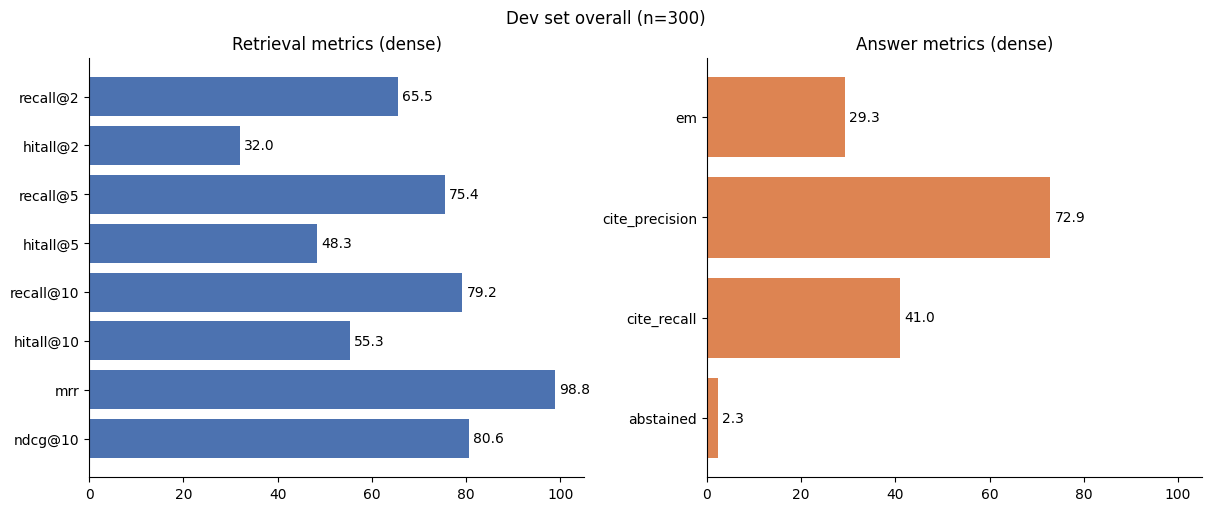

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
retr = {k: v for k, v in OVERALL.items() if k.startswith(("recall", "hitall")) or k in ("mrr", "ndcg@10")}
answ = {k: v for k, v in OVERALL.items() if k in ("em", "f1", "cite_precision", "cite_recall", "abstained")}
for ax, d, c, t in [(axes[0], retr, "#4C72B0", "Retrieval metrics (dense)"),
                    (axes[1], answ, "#DD8452", "Answer metrics (dense)")]:
    keys = list(d)[::-1]
    bars = ax.barh(keys, [d[k] for k in keys], color=c)
    ax.bar_label(bars, fmt="%.1f", padding=3)
    ax.set_xlim(0, 105); ax.set_title(t)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Dev set overall (n={OVERALL_N})")
fig.savefig("overall_metrics.png", dpi=200)
plt.show()

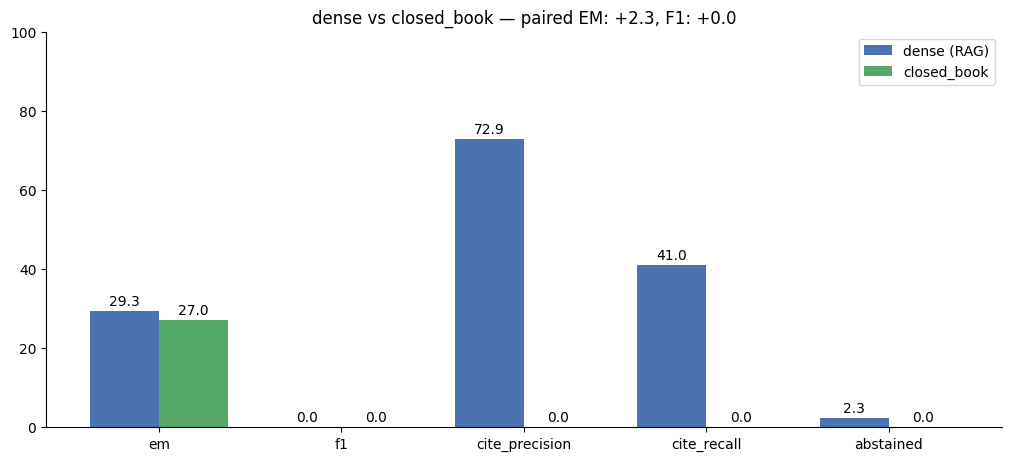

In [50]:
metrics = ["em", "f1", "cite_precision", "cite_recall", "abstained"]
x = np.arange(len(metrics)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
b1 = ax.bar(x - w/2, [OVERALL.get(m, 0.0) for m in metrics], w, label="dense (RAG)", color="#4C72B0")
b2 = ax.bar(x + w/2, [CLOSED_BOOK.get(m, 0.0) for m in metrics], w, label="closed_book", color="#55A868")
ax.bar_label(b1, fmt="%.1f", padding=2); ax.bar_label(b2, fmt="%.1f", padding=2)
ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylim(0, 100); ax.legend()
if PAIRED:
    ax.set_title(f"dense vs closed_book — paired EM: {PAIRED.get('em', 0.0):+.1f}, F1: {PAIRED.get('f1', 0.0):+.1f}")
else:
    ax.set_title("dense vs closed_book")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("dense_vs_closedbook.png", dpi=200)
plt.show()

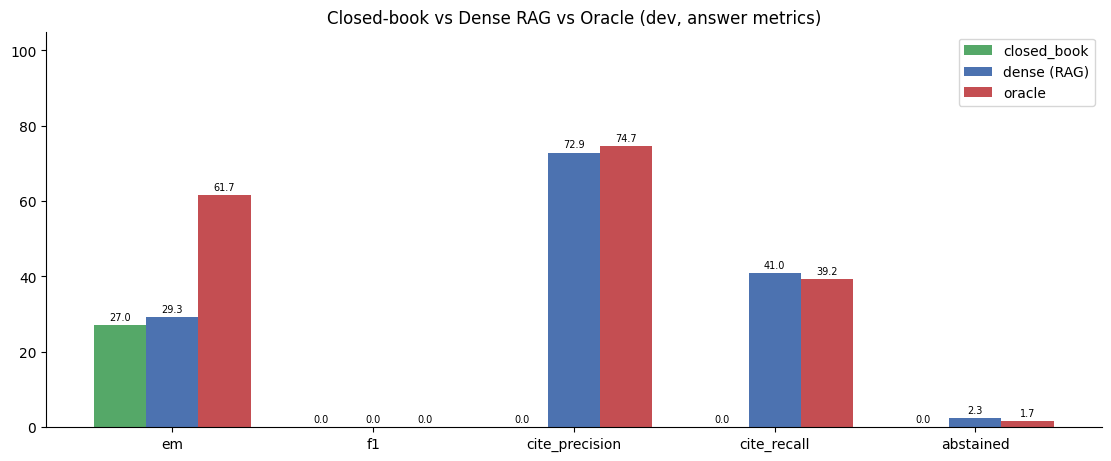

In [51]:
metrics = ["em", "f1", "cite_precision", "cite_recall", "abstained"]
systems = [("closed_book", CLOSED_BOOK, "#55A868"),
           ("dense (RAG)", OVERALL, "#4C72B0"),
           ("oracle", ORACLE, "#C44E52")]
x = np.arange(len(metrics)); w = 0.26
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
for i, (label, vals, color) in enumerate(systems):
    bars = ax.bar(x + (i - 1) * w, [vals.get(m, 0.0) for m in metrics], w, label=label, color=color)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylim(0, 105); ax.legend()
ax.set_title("Closed-book vs Dense RAG vs Oracle (dev, answer metrics)")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("three_systems.png", dpi=200)
plt.show()

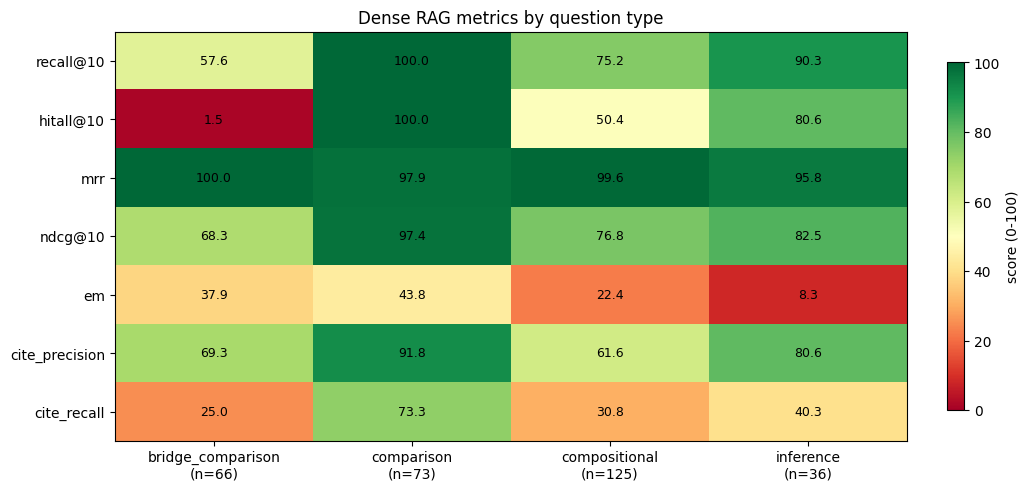

In [52]:
TYPES = list(BY_TYPE)
METRICS = [m for m in ("recall@10", "hitall@10", "mrr", "ndcg@10", "em", "f1", "cite_precision", "cite_recall")
           if TYPES and all(m in BY_TYPE[t] for t in TYPES)]
if not TYPES or not METRICS:
    print("داده‌ای برای heatmap نیست")
else:
    M = np.array([[BY_TYPE[t][m] for t in TYPES] for m in METRICS])
    fig, ax = plt.subplots(figsize=(1.8 * len(TYPES) + 3, 4.8), constrained_layout=True)
    im = ax.imshow(M, cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(TYPES)))
    ax.set_xticklabels([f"{t}\n(n={TYPE_N[t]})" for t in TYPES])
    ax.set_yticks(range(len(METRICS))); ax.set_yticklabels(METRICS)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=9)
    ax.set_title("Dense RAG metrics by question type")
    fig.colorbar(im, ax=ax, shrink=0.85, label="score (0-100)")
    fig.savefig("metrics_by_type.png", dpi=200)
    plt.show()

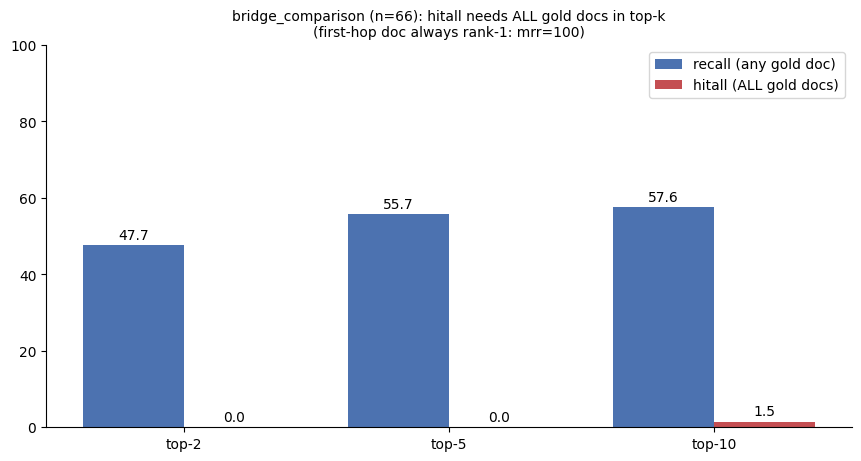

In [53]:
bridge = next((t for t in BY_TYPE if "bridge" in t), None)
if bridge is None:
    print("نوع bridge در خروجی نیست")
else:
    B = BY_TYPE[bridge]; ks = ["2", "5", "10"]
    x = np.arange(3); w = 0.38
    fig, ax = plt.subplots(figsize=(8.5, 4.5), constrained_layout=True)
    b1 = ax.bar(x - w/2, [B[f"recall@{k}"] for k in ks], w, label="recall (any gold doc)", color="#4C72B0")
    b2 = ax.bar(x + w/2, [B[f"hitall@{k}"] for k in ks], w, label="hitall (ALL gold docs)", color="#C44E52")
    ax.bar_label(b1, fmt="%.1f", padding=2); ax.bar_label(b2, fmt="%.1f", padding=2)
    ax.set_xticks(x); ax.set_xticklabels([f"top-{k}" for k in ks])
    ax.set_ylim(0, 100); ax.legend()
    ax.set_title(f"{bridge} (n={TYPE_N[bridge]}): hitall needs ALL gold docs in top-k\n(first-hop doc always rank-1: mrr={B.get('mrr', 0):.0f})", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    fig.savefig("bridge_hitall_artifact.png", dpi=200)
    plt.show()

In [54]:
STD_ID = "404722145"
GITHUB_URL = "https://github.com/mohammad-hossein-k-gh/Advanced-NLP_Phase1"
GITHUB_COMMIT = "YOUR_COMMIT_HASH"

EMBEDDING_MODEL_NAME = "Qwen/Qwen3-Embedding-4B"
LLM_MODEL_NAME = "Qwen/Qwen3-8B"

REPORT_PATH = OUTPUT_DIR / "report.pdf"

In [55]:
!pip install reportlab weasyprint -q

from pathlib import Path
import shutil
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle,
    PageBreak, Image, KeepTogether
)
from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER, TA_JUSTIFY
from xml.sax.saxutils import escape
from weasyprint import HTML

OUTPUT_DIR = Path("/kaggle/working/NLP_phase1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- پیدا کردن و کپی نمودارها از محل واقعی savefig ----
FIGURE_NAMES = [
    "overall_metrics.png",
    "dense_vs_closedbook.png",
    "three_systems.png",
    "metrics_by_type.png",
    "bridge_hitall_artifact.png",
]

search_roots = [
    Path("/kaggle/working"),
    Path.cwd(),
    OUTPUT_DIR,
]

copied = {}
for name in FIGURE_NAMES:
    found = None
    for root in search_roots:
        cand = root / name
        if cand.exists():
            found = cand
            break
        # جست‌وجوی یک سطح عمیق‌تر
        hits = list(root.rglob(name))
        if hits:
            found = hits[0]
            break
    if found is None:
        print("MISSING:", name)
        continue
    dest = FIG_DIR / name
    if found.resolve() != dest.resolve():
        shutil.copy2(found, dest)
    copied[name] = dest
    print("OK:", name, "←", found)

# ---- متریک‌ها از پارس نوت‌بوک ----
# انتظار: CLOSED_BOOK, OVERALL(=dense), ORACLE, BY_TYPE, TYPE_N, PAIRED, OVERALL_N
def f(d, k, default="—"):
    if not isinstance(d, dict) or k not in d:
        return default
    v = d[k]
    return f"{v:.1f}" if isinstance(v, (int, float)) else str(v)

def gap(a, b, k):
    if k not in a or k not in b:
        return "—"
    return f"{a[k] - b[k]:+.1f}"

cb = CLOSED_BOOK if "CLOSED_BOOK" in globals() else {}
dens = OVERALL if "OVERALL" in globals() else {}
ora = ORACLE if "ORACLE" in globals() else {}
by_type = BY_TYPE if "BY_TYPE" in globals() else {}
type_n = TYPE_N if "TYPE_N" in globals() else {}
paired = PAIRED if "PAIRED" in globals() else {}
n_dev = OVERALL_N if "OVERALL_N" in globals() else 300

STD_ID = "404722145"
GITHUB_URL = "https://github.com/mohammad-hossein-k-gh/Advanced-NLP_Phase1"
GITHUB_COMMIT = "YOUR_COMMIT_HASH"
EMBEDDING_MODEL = "Qwen/Qwen3-Embedding-4B"
LLM_MODEL = "Qwen/Qwen3-8B"

# ===================== ENGLISH REPORT =====================
styles = getSampleStyleSheet()
styles.add(ParagraphStyle(name="TitleEn", fontName="Helvetica-Bold", fontSize=14, leading=18, alignment=TA_CENTER, spaceAfter=6))
styles.add(ParagraphStyle(name="SubTitle", fontName="Helvetica", fontSize=11, leading=14, alignment=TA_CENTER, spaceAfter=10))
styles.add(ParagraphStyle(name="H1", fontName="Helvetica-Bold", fontSize=11, leading=14, spaceBefore=10, spaceAfter=5))
styles.add(ParagraphStyle(name="H2", fontName="Helvetica-Bold", fontSize=10, leading=13, spaceBefore=8, spaceAfter=4))
styles.add(ParagraphStyle(name="Body", fontName="Helvetica", fontSize=9, leading=12, alignment=TA_JUSTIFY, spaceAfter=4))
styles.add(ParagraphStyle(name="Small", fontName="Helvetica", fontSize=8, leading=10, spaceAfter=3))
styles.add(ParagraphStyle(name="Caption", fontName="Helvetica-Oblique", fontSize=8, leading=10, alignment=TA_CENTER, spaceAfter=8))

def p(text, style="Body"):
    return Paragraph(text, styles[style])

def make_table(data, col_widths):
    t = Table(data, colWidths=col_widths, repeatRows=1)
    t.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.Color(0.85, 0.85, 0.9)),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTSIZE", (0, 0), (-1, -1), 7),
        ("ALIGN", (0, 0), (-1, -1), "CENTER"),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.grey),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.Color(0.96, 0.96, 0.98)]),
        ("TOPPADDING", (0, 0), (-1, -1), 3),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 3),
    ]))
    return t

def add_fig(story, name, caption, width=15.5*cm):
    path = FIG_DIR / name
    if not path.exists():
        story.append(p(f"[Figure missing: {name}]", "Small"))
        return
    img = Image(str(path), width=width, height=width * 0.52)
    img.hAlign = "CENTER"
    story.append(KeepTogether([img, p(caption, "Caption")]))

story = []
story.append(p("Advanced Natural Language Processing", "TitleEn"))
story.append(p("Phase 1 — Dense Retrieval & Multi-hop Question Answering", "SubTitle"))

info = [
    ["Student ID", STD_ID],
    ["GitHub Repository", GITHUB_URL],
    ["Commit", GITHUB_COMMIT],
    ["Embedding Model", EMBEDDING_MODEL],
    ["Generation Model", LLM_MODEL],
    ["Hardware", "2× NVIDIA Tesla T4 (Kaggle), float16"],
]
info_t = Table(info, colWidths=[4.2*cm, 11.8*cm])
info_t.setStyle(TableStyle([
    ("FONTNAME", (0, 0), (0, -1), "Helvetica-Bold"),
    ("FONTSIZE", (0, 0), (-1, -1), 8.5),
    ("BOTTOMPADDING", (0, 0), (-1, -1), 3),
]))
story.append(info_t)
story.append(Spacer(1, 8))

story.append(p("1. Introduction and System Overview", "H1"))
story.append(p(
    "This phase builds a standard evaluation pipeline and baselines for multi-hop question answering "
    "over a fixed passage corpus. We evaluate retrieval quality, answer exactness, citation behavior, "
    "and abstention under three information conditions."
))
story.append(make_table([
    ["System", "Context to LLM", "Purpose"],
    ["Closed-book", "None", "Lower bound: parametric knowledge only"],
    ["Dense RAG", "Top-5 dense passages", "Realistic end-to-end pipeline"],
    ["Oracle-context", "Gold documents", "Upper bound with perfect retrieval"],
], [3.2*cm, 5.5*cm, 7.3*cm]))
story.append(p(
    f"Retrieval uses <b>{escape(EMBEDDING_MODEL)}</b> (last-token pooling, L2-normalized cosine search). "
    f"Generation uses <b>{escape(LLM_MODEL)}</b> with a strict zero-shot prompt (short answers, optional "
    f"[pXXXXX] citations, explicit abstention). Metrics below come from official score.py on dev (n={n_dev})."
))

story.append(p("2. Overall Results", "H1"))
story.append(p("2.1 Answer and citation metrics", "H2"))
story.append(make_table([
    ["System", "EM", "F1", "Cite-P", "Cite-R", "Abstained"],
    ["Closed-book", f(cb,"em"), f(cb,"f1"), f(cb,"cite_precision"), f(cb,"cite_recall"), f(cb,"abstained")],
    ["Dense RAG", f(dens,"em"), f(dens,"f1"), f(dens,"cite_precision"), f(dens,"cite_recall"), f(dens,"abstained")],
    ["Oracle", f(ora,"em"), f(ora,"f1"), f(ora,"cite_precision"), f(ora,"cite_recall"), f(ora,"abstained")],
], [2.6*cm, 2.4*cm, 2.4*cm, 2.6*cm, 2.6*cm, 2.4*cm]))
add_fig(story, "three_systems.png",
        "Figure 1. Closed-book vs Dense RAG vs Oracle — answer metrics (dev).")

story.append(p("2.2 Retrieval ranking metrics", "H2"))
story.append(make_table([
    ["System", "R@2", "R@5", "R@10", "H@2", "H@5", "H@10", "MRR", "nDCG@10"],
    ["Closed-book", f(cb,"recall@2"), f(cb,"recall@5"), f(cb,"recall@10"),
     f(cb,"hitall@2"), f(cb,"hitall@5"), f(cb,"hitall@10"), f(cb,"mrr"), f(cb,"ndcg@10")],
    ["Dense RAG", f(dens,"recall@2"), f(dens,"recall@5"), f(dens,"recall@10"),
     f(dens,"hitall@2"), f(dens,"hitall@5"), f(dens,"hitall@10"), f(dens,"mrr"), f(dens,"ndcg@10")],
    ["Oracle", f(ora,"recall@2"), f(ora,"recall@5"), f(ora,"recall@10"),
     f(ora,"hitall@2"), f(ora,"hitall@5"), f(ora,"hitall@10"), f(ora,"mrr"), f(ora,"ndcg@10")],
], [2.5*cm, 1.6*cm, 1.6*cm, 1.7*cm, 1.6*cm, 1.6*cm, 1.7*cm, 1.5*cm, 1.8*cm]))
add_fig(story, "overall_metrics.png",
        "Figure 2. Overall metric panels parsed from score.py.")

story.append(p(
    f"Dense RAG reaches MRR={f(dens,'mrr')} and nDCG@10={f(dens,'ndcg@10')}, but HitAll@10 is only "
    f"{f(dens,'hitall@10')}: early ranking is strong while the full gold set is often incomplete for multi-hop items. "
    f"Oracle raises EM to {f(ora,'em')} and F1 to {f(ora,'f1')}."
))

story.append(PageBreak())
story.append(p("3. Dense vs Closed-book", "H1"))
add_fig(story, "dense_vs_closedbook.png",
        "Figure 3. Dense RAG versus Closed-book (paired comparison from score.py).")
if paired:
    story.append(p(
        f"Paired differences (Dense − Closed-book) include EM={f(paired,'em')}, F1={f(paired,'f1')}, "
        f"Recall@10={f(paired,'recall@10')}, HitAll@10={f(paired,'hitall@10')}."
    ))

story.append(p("4. Results by Question Type", "H1"))
story.append(p(
    "Development questions are typed as comparison, bridge_comparison, compositional, and inference. "
    "The heatmap below summarizes Dense RAG type-level scores."
))
add_fig(story, "metrics_by_type.png",
        "Figure 4. Dense RAG metrics by question type (heatmap).")

# type table from BY_TYPE
type_order = [t for t in ["comparison", "bridge_comparison", "compositional", "inference"] if t in by_type]
if type_order:
    rows = [["type", "n", "EM", "F1", "R@10", "H@10", "MRR", "nDCG@10", "Abs."]]
    for t in type_order:
        m = by_type[t]
        rows.append([
            t, str(type_n.get(t, "")),
            f(m, "em"), f(m, "f1"), f(m, "recall@10"), f(m, "hitall@10"),
            f(m, "mrr"), f(m, "ndcg@10"), f(m, "abstained"),
        ])
    story.append(make_table(rows, [2.6*cm, 1.2*cm, 1.5*cm, 1.5*cm, 1.6*cm, 1.6*cm, 1.5*cm, 1.8*cm, 1.5*cm]))

story.append(p("5. Bridge comparison: recall vs hitall", "H1"))
add_fig(story, "bridge_hitall_artifact.png",
        "Figure 5. Bridge questions: high recall can coexist with near-zero hitall when not ALL gold docs are retrieved.")
story.append(p(
    "On bridge_comparison items the first relevant document is often ranked at position 1 (high MRR), "
    "yet HitAll stays near zero because the intermediate/second gold document is missing from top-k. "
    "This is the main multi-hop retrieval bottleneck."
))

story.append(p("6. Pairwise gaps (numeric)", "H1"))
story.append(make_table([
    ["Metric", "Dense − Closed-book", "Oracle − Dense"],
    ["EM", gap(dens, cb, "em"), gap(ora, dens, "em")],
    ["F1", gap(dens, cb, "f1"), gap(ora, dens, "f1")],
    ["Recall@10", gap(dens, cb, "recall@10"), gap(ora, dens, "recall@10")],
    ["HitAll@10", gap(dens, cb, "hitall@10"), gap(ora, dens, "hitall@10")],
    ["MRR", gap(dens, cb, "mrr"), gap(ora, dens, "mrr")],
    ["nDCG@10", gap(dens, cb, "ndcg@10"), gap(ora, dens, "ndcg@10")],
    ["Cite-P", gap(dens, cb, "cite_precision"), gap(ora, dens, "cite_precision")],
], [3.5*cm, 5.5*cm, 5.5*cm]))

story.append(PageBreak())
story.append(p("7. Error Analysis", "H1"))
story.append(p("7.1 Closed-book fails while Dense succeeds", "H2"))
story.append(p(
    "<b>qid q0001 (comparison).</b> Country-of-origin comparison for two films. Dense retrieves both origin "
    "passages; closed-book lacks precise metadata and errs more often.", "Small"))
story.append(p("7.2 Multi-hop retrieval failure", "H2"))
story.append(p(
    "Bridge items need multiple gold documents. Entity pages appear in top-k, intermediate biography pages do not; "
    "the LLM then abstains or answers incorrectly.", "Small"))
story.append(p("7.3 Partial evidence → coarse answers", "H2"))
story.append(p(
    "Compositional questions often retrieve a related document but the answer is a country instead of a city, "
    "or a broader category than the gold span.", "Small"))
story.append(p("7.4 Oracle residual errors", "H2"))
story.append(p(
    f"With gold context, EM={f(ora,'em')} and F1={f(ora,'f1')}. Remaining errors are mostly format/alias mismatches "
    "and occasional yes/no mistakes.", "Small"))
story.append(p("7.5 Abstention", "H2"))
story.append(p(
    f"Dense RAG abstention rate is {f(dens,'abstained')}%. The strict prompt reduces hallucination but can drop "
    "answerable items with partial evidence.", "Small"))

story.append(p("8. Implementation Details", "H1"))
story.append(p(
    "Corpus: 3,882 passages; embedding input “Title / Passage”, max length 1024; exhaustive cosine search; "
    "top-10 stored, top-5 passed to the generator; chat generation with max_new_tokens=128; official score.py evaluation."
))
story.append(p("9. Limitations", "H1"))
story.append(p(
    "Two T4 GPUs in float16; limited hyper-parameter search; single Qwen3 family for embedder and LLM; "
    "hidden labels unavailable locally; qualitative error analysis on a subset of failures."
))
story.append(p("10. AI-tool transparency", "H1"))
story.append(p(
    "AI assistants were used for coding help and report structuring. Final design decisions and interpretation "
    "were made by the student."
))
story.append(Spacer(1, 8))
story.append(p(f"Repository: {escape(GITHUB_URL)}", "Small"))
story.append(p(f"Commit: {escape(GITHUB_COMMIT)}", "Small"))

REPORT_EN = OUTPUT_DIR / "report_eng.pdf"
doc = SimpleDocTemplate(
    str(REPORT_EN), pagesize=A4,
    rightMargin=1.3*cm, leftMargin=1.3*cm, topMargin=1.2*cm, bottomMargin=1.2*cm,
    title="Phase 1 QA/RAG Report", author=STD_ID,
)
doc.build(story)
print("English report:", REPORT_EN, "KB:", round(REPORT_EN.stat().st_size/1024, 1))

# ===================== PERSIAN REPORT =====================
def fig_tag(name, caption):
    path = FIG_DIR / name
    if not path.exists():
        return f"<p class='note'>[نمودار موجود نیست: {name}]</p>"
    return f"""
    <div class="fig">
      <img src="{path.as_uri()}" alt="{caption}"/>
      <div class="cap">{caption}</div>
    </div>"""

def type_rows_fa():
    rows = ""
    for t in type_order:
        m = by_type[t]
        rows += f"""<tr>
          <td>{t}</td><td>{type_n.get(t,'')}</td>
          <td>{f(m,'em')}</td><td>{f(m,'f1')}</td>
          <td>{f(m,'recall@10')}</td><td>{f(m,'hitall@10')}</td>
          <td>{f(m,'mrr')}</td><td>{f(m,'ndcg@10')}</td><td>{f(m,'abstained')}</td>
        </tr>"""
    return rows

html = f"""
<!DOCTYPE html>
<html lang="fa" dir="rtl">
<head>
<meta charset="utf-8"/>
<style>
  @import url('https://cdn.jsdelivr.net/gh/rastikerdar/vazirmatn@v33.003/Vazirmatn-font-face.css');
  @page {{ size: A4; margin: 1.5cm; }}
  body {{ font-family: Vazirmatn, Tahoma, sans-serif; font-size: 10pt; line-height: 1.65; direction: rtl; text-align: justify; color:#222; }}
  h1 {{ font-size: 15pt; text-align: center; margin: 0 0 2px 0; }}
  h2 {{ font-size: 12pt; text-align: center; margin: 0 0 14px 0; color:#333; }}
  h3 {{ font-size: 11pt; border-bottom: 1px solid #ccc; padding-bottom: 3px; margin-top: 16px; }}
  h4 {{ font-size: 10pt; margin: 10px 0 4px 0; }}
  table.meta td {{ padding: 3px 6px; font-size: 9pt; }}
  table.meta td:first-child {{ font-weight: bold; width: 30%; }}
  table.data {{ width: 100%; border-collapse: collapse; margin: 8px 0 12px; font-size: 8pt; }}
  table.data th, table.data td {{ border: 1px solid #bbb; padding: 4px 3px; text-align: center; }}
  table.data th {{ background: #e8eaf0; }}
  table.data tr:nth-child(even) td {{ background: #f7f8fb; }}
  .en {{ direction: ltr; unicode-bidi: isolate; }}
  .example {{ background:#f8f9fc; border-right: 3px solid #6b7bb5; padding: 8px 10px; margin: 8px 0; font-size: 9pt; }}
  .fig {{ text-align: center; margin: 12px 0 16px 0; }}
  .fig img {{ max-width: 100%; height: auto; }}
  .cap {{ font-size: 8.5pt; color:#444; margin-top: 4px; font-style: italic; }}
  .note {{ font-size: 9pt; color:#666; }}
  .footer {{ margin-top: 20px; text-align: center; font-size: 9pt; color:#555; }}
</style>
</head>
<body>
<h1>پروژه درس پردازش زبان طبیعی پیشرفته</h1>
<h2>فاز ۱ — سنجش و بازیابی متراکم و پرسش‌وپاسخ چندگامی</h2>

<table class="meta">
  <tr><td>شناسه دانشجو</td><td>{STD_ID}</td></tr>
  <tr><td>مخزن GitHub</td><td class="en">{GITHUB_URL}</td></tr>
  <tr><td>شناسه Commit</td><td class="en">{GITHUB_COMMIT}</td></tr>
  <tr><td>مدل Embedding</td><td class="en">{EMBEDDING_MODEL}</td></tr>
  <tr><td>مدل تولید پاسخ</td><td class="en">{LLM_MODEL}</td></tr>
  <tr><td>سخت‌افزار</td><td>دو GPU از نوع Tesla T4، دقت float16</td></tr>
</table>

<h3>۱. مقدمه و سامانه‌ها</h3>
<p>
سه سامانه Closed-book، Dense RAG و Oracle-context روی مجموعه توسعه (n={n_dev}) با اسکریپت رسمی
<span class="en">score.py</span> ارزیابی شدند. بازیابی با
<span class="en">{EMBEDDING_MODEL}</span> و تولید پاسخ با
<span class="en">{LLM_MODEL}</span> انجام شده است.
</p>
<table class="data">
  <tr><th>سامانه</th><th>زمینه</th><th>نقش</th></tr>
  <tr><td>Closed-book</td><td>هیچ</td><td>کران پایین</td></tr>
  <tr><td>Dense RAG</td><td>پنج سند برتر</td><td>خط لوله واقعی</td></tr>
  <tr><td>Oracle</td><td>اسناد طلایی</td><td>کران بالا</td></tr>
</table>

<h3>۲. نتایج کلی</h3>
<table class="data">
  <tr><th>سامانه</th><th>EM</th><th>F1</th><th>Cite-P</th><th>Cite-R</th><th>Abstained</th></tr>
  <tr><td>Closed-book</td><td>{f(cb,'em')}</td><td>{f(cb,'f1')}</td><td>{f(cb,'cite_precision')}</td><td>{f(cb,'cite_recall')}</td><td>{f(cb,'abstained')}</td></tr>
  <tr><td>Dense RAG</td><td>{f(dens,'em')}</td><td>{f(dens,'f1')}</td><td>{f(dens,'cite_precision')}</td><td>{f(dens,'cite_recall')}</td><td>{f(dens,'abstained')}</td></tr>
  <tr><td>Oracle</td><td>{f(ora,'em')}</td><td>{f(ora,'f1')}</td><td>{f(ora,'cite_precision')}</td><td>{f(ora,'cite_recall')}</td><td>{f(ora,'abstained')}</td></tr>
</table>
{fig_tag("three_systems.png", "شکل ۱. مقایسه سه سامانه روی معیارهای پاسخ")}

<table class="data">
  <tr><th>سامانه</th><th>R@2</th><th>R@5</th><th>R@10</th><th>H@2</th><th>H@5</th><th>H@10</th><th>MRR</th><th>nDCG@10</th></tr>
  <tr><td>Closed-book</td><td>{f(cb,'recall@2')}</td><td>{f(cb,'recall@5')}</td><td>{f(cb,'recall@10')}</td><td>{f(cb,'hitall@2')}</td><td>{f(cb,'hitall@5')}</td><td>{f(cb,'hitall@10')}</td><td>{f(cb,'mrr')}</td><td>{f(cb,'ndcg@10')}</td></tr>
  <tr><td>Dense RAG</td><td>{f(dens,'recall@2')}</td><td>{f(dens,'recall@5')}</td><td>{f(dens,'recall@10')}</td><td>{f(dens,'hitall@2')}</td><td>{f(dens,'hitall@5')}</td><td>{f(dens,'hitall@10')}</td><td>{f(dens,'mrr')}</td><td>{f(dens,'ndcg@10')}</td></tr>
  <tr><td>Oracle</td><td>{f(ora,'recall@2')}</td><td>{f(ora,'recall@5')}</td><td>{f(ora,'recall@10')}</td><td>{f(ora,'hitall@2')}</td><td>{f(ora,'hitall@5')}</td><td>{f(ora,'hitall@10')}</td><td>{f(ora,'mrr')}</td><td>{f(ora,'ndcg@10')}</td></tr>
</table>
{fig_tag("overall_metrics.png", "شکل ۲. پنل معیارهای overall از خروجی score.py")}

<p>
Dense با MRR={f(dens,'mrr')} و HitAll@10={f(dens,'hitall@10')} نشان می‌دهد رتبه‌بندی اولیه قوی است،
اما مجموعه کامل اسناد طلایی در سوالات چندگامی اغلب ناقص می‌ماند. Oracle به EM={f(ora,'em')} و F1={f(ora,'f1')} می‌رسد.
</p>

<h3>۳. Dense در برابر Closed-book</h3>
{fig_tag("dense_vs_closedbook.png", "شکل ۳. مقایسه جفتی Dense و Closed-book")}
<p>تفاضل‌های جفتی (Dense − Closed-book) از score.py: EM={f(paired,'em')}، F1={f(paired,'f1')}، Recall@10={f(paired,'recall@10')}، HitAll@10={f(paired,'hitall@10')}.</p>

<h3>۴. به تفکیک نوع سوال</h3>
{fig_tag("metrics_by_type.png", "شکل ۴. نقشه حرارتی معیارهای Dense به تفکیک نوع سوال")}
<table class="data">
  <tr><th>type</th><th>n</th><th>EM</th><th>F1</th><th>R@10</th><th>H@10</th><th>MRR</th><th>nDCG@10</th><th>Abs.</th></tr>
  {type_rows_fa()}
</table>

<h3>۵. شکاف recall و hitall در bridge</h3>
{fig_tag("bridge_hitall_artifact.png", "شکل ۵. در bridge، recall بالا می‌تواند با hitall نزدیک صفر همراه باشد")}
<p>
در bridge_comparison معمولاً سند اول مرتبط در رتبه ۱ است (MRR بالا)، اما سند دوم/واسط در top-k نیست؛
به همین دلیل HitAll نزدیک صفر می‌ماند. این گلوگاه اصلی بازیابی چندگامی است.
</p>

<h3>۶. تفاضل عددی سامانه‌ها</h3>
<table class="data">
  <tr><th>معیار</th><th>Dense − Closed-book</th><th>Oracle − Dense</th></tr>
  <tr><td>EM</td><td>{gap(dens,cb,'em')}</td><td>{gap(ora,dens,'em')}</td></tr>
  <tr><td>F1</td><td>{gap(dens,cb,'f1')}</td><td>{gap(ora,dens,'f1')}</td></tr>
  <tr><td>Recall@10</td><td>{gap(dens,cb,'recall@10')}</td><td>{gap(ora,dens,'recall@10')}</td></tr>
  <tr><td>HitAll@10</td><td>{gap(dens,cb,'hitall@10')}</td><td>{gap(ora,dens,'hitall@10')}</td></tr>
  <tr><td>MRR</td><td>{gap(dens,cb,'mrr')}</td><td>{gap(ora,dens,'mrr')}</td></tr>
  <tr><td>nDCG@10</td><td>{gap(dens,cb,'ndcg@10')}</td><td>{gap(ora,dens,'ndcg@10')}</td></tr>
  <tr><td>Cite-P</td><td>{gap(dens,cb,'cite_precision')}</td><td>{gap(ora,dens,'cite_precision')}</td></tr>
</table>

<h3>۷. تحلیل خطا</h3>
<div class="example"><b>موفقیت Dense در برابر Closed-book:</b> در q0001 اسناد مبدأ کشور بازیابی و پاسخ درست تولید می‌شود.</div>
<div class="example"><b>شکست چندگامی:</b> صفحات موجودیت پیدا می‌شوند؛ صفحه واسط از دست می‌رود.</div>
<div class="example"><b>پاسخ کلی:</b> شواهد ناقص → کشور به‌جای شهر.</div>
<div class="example"><b>اوراکل:</b> EM={f(ora,'em')} و F1={f(ora,'f1')}؛ خطای باقی‌مانده بیشتر قالبی است.</div>
<div class="example"><b>خودداری:</b> نرخ abstain در Dense برابر {f(dens,'abstained')}٪ است.</div>

<h3>۸. جزئیات، محدودیت‌ها و شفافیت</h3>
<p>
پیکره ۳۸۸۲ گذرگاه؛ top-10 ذخیره و top-5 برای تولید؛ سخت‌افزار دو T4 با float16؛ جست‌وجوی فراپارامتر محدود.
از دستیارهای هوش مصنوعی برای کدنویسی و ساختار گزارش استفاده شده؛ تصمیم نهایی با دانشجو بوده است.
</p>

<div class="footer">
مخزن: <span class="en">{GITHUB_URL}</span><br/>
Commit: <span class="en">{GITHUB_COMMIT}</span>
</div>
</body></html>
"""

REPORT_FA = OUTPUT_DIR / "report_fa.pdf"
HTML(string=html).write_pdf(str(REPORT_FA))
print("Persian report:", REPORT_FA, "KB:", round(REPORT_FA.stat().st_size/1024, 1))

# کپی report.pdf برای ZIP
REPORT_PATH = OUTPUT_DIR / "report.pdf"
shutil.copy2(REPORT_FA, REPORT_PATH)  # یا REPORT_EN اگر نسخه انگلیسی می‌خواهی
print("Copied submission report →", REPORT_PATH)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 328.9/328.9 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 49.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 829.4/829.4 kB 36.6 MB/s eta 0:00:00
OK: overall_metrics.png ← /kaggle/working/overall_metrics.png
OK: dense_vs_closedbook.png ← /kaggle/working/dense_vs_closedbook.png
OK: three_systems.png ← /kaggle/working/three_systems.png
OK: metrics_by_type.png ← /kaggle/working/metrics_by_type.png
OK: bridge_hitall_artifact.png ← /kaggle/working/bridge_hitall_artifact.png
English report: /kaggle/working/NLP_phase1/report_eng.pdf KB: 444.1
Persian report: /kaggle/working/NLP_phase1/report_fa.pdf KB: 421.0
Copied submission report → /kaggle/working/NLP_phase1/report.pdf


In [56]:
# ===================== ساخت ZIP نهایی تحویل =====================
import json
import zipfile
from pathlib import Path

STD_ID = "404722145"
SUBMISSION_ZIP = Path("/kaggle/working") / f"P1_{STD_ID}.zip"
REPORT_PATH = OUTPUT_DIR / "report.pdf"   # گزارش فارسی (کپی‌شده در سل گزارش)

required_run_dirs = [
    RUN_PATHS["closed_book"],
    RUN_PATHS["oracle_context"],
    RUN_PATHS["dense_rag"],
    RUN_PATHS["hidden_closed_book"],
    RUN_PATHS["hidden_dense_rag"],
]
selfcheck_dir = OUTPUT_DIR / "runs" / "selfcheck"
all_dirs = required_run_dirs + [selfcheck_dir]
expected_counts = [300, 300, 300, 300, 300, 50]

# ---------- ۱) صحت‌سنجی قبل از زیپ ----------
EXPECTED_FIELDS = {"qid", "answer", "retrieved", "cited", "abstained"}

assert REPORT_PATH.exists(), f"گزارش پیدا نشد: {REPORT_PATH}"
for run_dir, n_exp in zip(all_dirs, expected_counts):
    pred = run_dir / "predictions.jsonl"
    assert pred.exists(), f"predictions پیدا نشد: {pred}"
    with pred.open(encoding="utf-8") as fh:
        first = json.loads(fh.readline())
    assert set(first.keys()) == EXPECTED_FIELDS, (
        f"{pred}: فیلدها باید دقیقاً {sorted(EXPECTED_FIELDS)} باشد — الان: {sorted(first.keys())}"
    )
    n = sum(1 for line in pred.open(encoding="utf-8") if line.strip())
    assert n == n_exp, f"{pred}: {n} رکورد — انتظار {n_exp}"

# ---------- ۲) ساخت ZIP (mode="w" همیشه از نو می‌نویسد، محتوای قدیمی نمی‌ماند) ----------
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(REPORT_PATH, arcname="report.pdf")
    for run_dir in all_dirs:
        for fp in sorted(run_dir.rglob("*")):
            if fp.is_file():
                zf.write(fp, arcname=str(fp.relative_to(OUTPUT_DIR)))

# ---------- ۳) تأیید نهایی ----------
with zipfile.ZipFile(SUBMISSION_ZIP) as zf:
    names = zf.namelist()
    print("ZIP contents:")
    for name in sorted(names):
        print("  ", name)
    assert "report.pdf" in names, "report.pdf در ریشه ZIP نیست"
    n_pred = sum(name.endswith("predictions.jsonl") for name in names)
    assert n_pred == 6, f"باید ۶ predictions.jsonl باشد (۵ ران + selfcheck) — الان {n_pred}"

print("\nSubmission ZIP:", SUBMISSION_ZIP)
print("ZIP size (MB):", round(SUBMISSION_ZIP.stat().st_size / (1024**2), 2))

ZIP contents:
   report.pdf
   runs/dev/closed_book/predictions.jsonl
   runs/dev/closed_book/run_config.yaml
   runs/dev/dense/predictions.jsonl
   runs/dev/dense/run_config.yaml
   runs/dev/oracle/predictions.jsonl
   runs/dev/oracle/run_config.yaml
   runs/hidden/closed_book/predictions.jsonl
   runs/hidden/closed_book/run_config.yaml
   runs/hidden/dense/predictions.jsonl
   runs/hidden/dense/run_config.yaml
   runs/selfcheck/predictions.jsonl

Submission ZIP: /kaggle/working/P1_404722145.zip
ZIP size (MB): 0.39
